# Дослідження PAM, WaveCluster, GMM і MCL
**1. Імпортуємо модулі для даних, алгоритмів, графіків і локального збереження.**
WaveCluster використовується як явно специфікований 2D Haar-DWT варіант,
а не як точна реплікація експериментів оригінальної статті. Детальний аналіз — у майбутньому звіті.

In [ ]:
from pathlib import Path
import copy
import os
import platform
import sys

ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "task.md").exists() and (p / "src").is_dir()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

from src.artifacts import Store, frame_info, write_json, write_requirements
from src.data import (
    Dataset,
    UCI_DATASETS,
    generate_suite,
    load_real,
    prepare,
    pca_record,
)
from src.algorithms import ALGORITHMS, default_params, run_algorithm
from src.experiments import tune, evaluate, stability, randomness_check
from src.benchmark import run_benchmarks
from src.visualization import (
    eda,
    preprocessing_plot,
    compare,
    intermediates,
    metric_figures,
    tuning_figures,
    stability_figures,
    benchmark_figures,
    scatter,
)

**2. Перевіряємо Python із локального `.venv` і відображаємо інформацію про середовище.**

In [ ]:
assert sys.prefix != sys.base_prefix, "Запустіть notebook через .venv"
assert (
    Path(sys.prefix).resolve() == (ROOT / ".venv").resolve()
), "Потрібен локальний .venv проєкту"
print(
    {
        "python": sys.version,
        "executable": sys.executable,
        "platform": platform.platform(),
    }
)

{'python': '3.14.3 (main, Feb  3 2026, 22:52:18) [Clang 21.1.4 ]', 'executable': '/home/yura4ka/Work/uni/clasterization_lab/.venv/bin/python', 'platform': 'Linux-7.2.3-arch1-3-x86_64-with-glibc2.44'}


**3. Визначаємо режим, випадковий стан, розміри вибірок і локальні шляхи.**
`LAB_MODE=quick` — перевірка всього конвеєра; `full` — розширений експеримент.
Обидва режими зберігають усі результати; повний не означає вичерпний перебір параметрів.

In [ ]:
MODE = os.environ.get("LAB_MODE", "full")
assert MODE in {"quick", "full"}
SEED = 42
MAX_SAMPLES = 360 if MODE == "quick" else 600
CONFIG = {
    "mode": MODE,
    "seed": SEED,
    "max_main_samples": MAX_SAMPLES,
    "algorithms": list(ALGORITHMS),
    "generators": ["PCG64", "MT19937"],
    "delta_relative": [0.001, 0.01, 0.05, 0.1],
    "synthetic_scaling": "common scalar (shape preserving)",
    "real_scaling": "median imputation + StandardScaler",
    "selection": "GMM: BIC; others: constrained silhouette; no reference labels",
    "warning": "Internal Euclidean metrics can prefer convex clusters",
}
print(CONFIG)

{'mode': 'full', 'seed': 42, 'max_main_samples': 600, 'algorithms': ['PAM', 'WaveCluster', 'GMM', 'MCL'], 'generators': ['PCG64', 'MT19937'], 'delta_relative': [0.001, 0.01, 0.05, 0.1], 'synthetic_scaling': 'common scalar (shape preserving)', 'real_scaling': 'median imputation + StandardScaler', 'selection': 'GMM: BIC; others: constrained silhouette; no reference labels', 'warning': 'Internal Euclidean metrics can prefer convex clusters'}


**4. Створюємо каталог поточного запуску, журнал і спільний стиль графіків.**

In [4]:
store = Store(ROOT, MODE)
store.json("config/experiment.json", CONFIG)
versions = store.environment()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
print("Локальні артефакти:", store.root)

Локальні артефакти: /home/yura4ka/Work/uni/clasterization_lab/artifacts/20261102T185251_247163Z_full


**5. Перевіряємо локальне збереження конфігурації та фіксуємо джерела методів.**

In [5]:
SOURCES = {
    "PAM": "https://doi.org/10.1002/9780470316801",
    "PAM_implementation": "https://python-kmedoids.readthedocs.io/",
    "WaveCluster": "https://www.vldb.org/conf/1998/p428.pdf",
    "MCL": "https://ir.cwi.nl/pub/9256",
    "GMM_implementation": "https://scikit-learn.org/stable/modules/mixture.html",
    "Wine": "https://archive.ics.uci.edu/dataset/109/wine",
    "Seeds": "https://www.kaggle.com/datasets/rwzhang/seeds-dataset",
    "DryBean": "https://archive.ics.uci.edu/dataset/602/dry+bean+dataset",
}
store.json("config/sources.json", SOURCES)
store.logger.info("Notebook started: %s", MODE)
display(pd.Series(SOURCES, name="source").to_frame())

,source
PAM,https://doi.org/10.1002/9780470316801
PAM_implementation,https://python-kmedoids.readthedocs.io/
WaveCluster,https://www.vldb.org/conf/1998/p428.pdf
MCL,https://ir.cwi.nl/pub/9256
GMM_implementation,https://scikit-learn.org/stable/modules/mixtur...
Wine,https://archive.ics.uci.edu/dataset/109/wine
Seeds,https://www.kaggle.com/datasets/rwzhang/seeds-...
DryBean,https://archive.ics.uci.edu/dataset/602/dry+be...


**6. Визначаємо джерела та локальний кеш реальних даних.**
Wine і Dry Bean завантажує `ucimlrepo`; Seeds — `kagglehub`, оскільки UCI API
не надає його через `ucimlrepo`. Прямих викликів `requests` немає.

In [6]:
RAW_DIR = ROOT / "data" / "raw"
real = {}
print("UCI identifiers:", UCI_DATASETS)
print("Cache:", RAW_DIR)

UCI identifiers: {'wine': 109, 'seeds': 236, 'dry_bean': 602}
Cache: /home/yura4ka/Work/uni/clasterization_lab/data/raw


**7. Завантажуємо Wine через бібліотеку або читаємо локальну копію.**

In [7]:
real["wine"] = load_real("wine", ROOT)
print(real["wine"].frame.shape)

(178, 13)


**8. Переглядаємо Wine: head, info, статистику, пропуски й дублікати.**

In [8]:
display(real["wine"].frame.head())
print(frame_info(real["wine"].frame))
display(real["wine"].frame.describe().T)
display(real["wine"].frame.isna().sum().to_frame("missing"))
print("Duplicate feature rows:", real["wine"].frame.duplicated().sum())

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Alcohol                       178 non-null    float64
 1   Malicacid                     178 non-null    float64
 2   Ash                           178 non-null    float64
 3   Alcalinity_of_ash             178 non-null    float64
 4   Magnesium                     178 non-null    int64  
 5   Total_phenols                 178 non-null    float64
 6   Flavanoids                    178 non-null    float64
 7   Nonflavanoid_phenols          178 non-null    float64
 8   Proanthocyanins               178 non-null    float64
 9   Color_intensity               178 non-null    float64
 10  Hue                           178 non-null    float64
 11  0D280_0D315_of_diluted_wines  178 non-null    float64
 12  Proline                       178 non-null    int64  
dtypes: float64(11), 

,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malicacid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
Color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


,missing
Alcohol,0
Malicacid,0
Ash,0
Alcalinity_of_ash,0
Magnesium,0
Total_phenols,0
Flavanoids,0
Nonflavanoid_phenols,0
Proanthocyanins,0
Color_intensity,0


Duplicate feature rows: 0


**9. Будуємо й зберігаємо гістограми, box plot, кореляції та розміри класів Wine.**


wine:
   Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  Total_phenols  Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity   Hue  0D280_0D315_of_diluted_wines  Proline
0    14.23       1.71  2.43               15.6        127           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92     1065
1    13.20       1.78  2.14               11.2        100           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40     1050
2    13.16       2.36  2.67               18.6        101           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17     1185
3    14.37       1.95  2.50               16.8        113           3.85        3.49                  0.24             2.18             7.80  0.86                          3.45     1480
4    13.24       2.59  2.87               21.0        118      

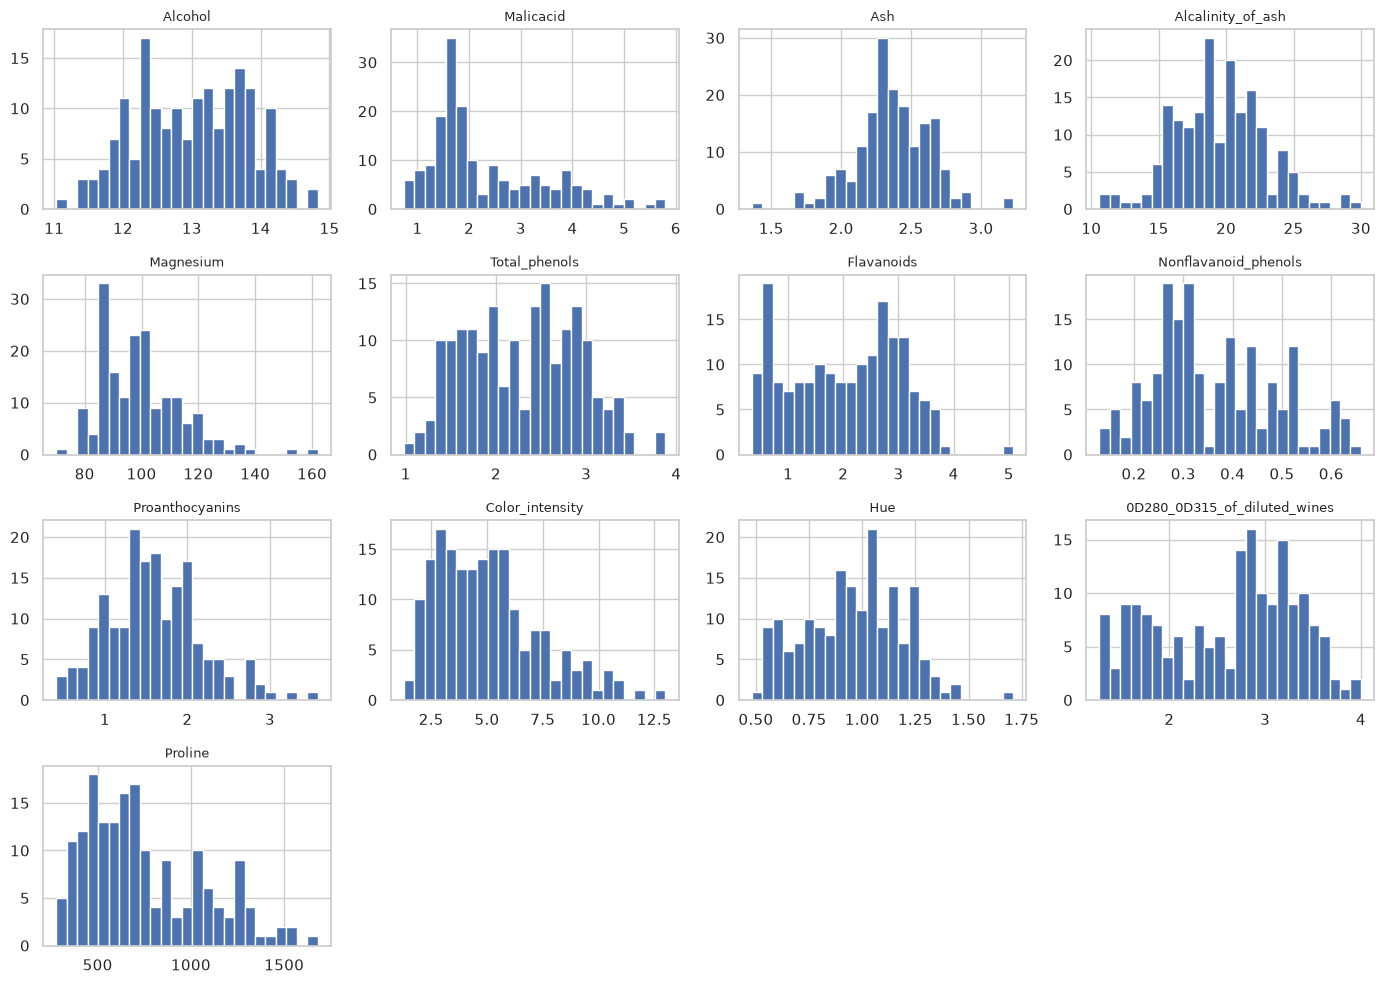

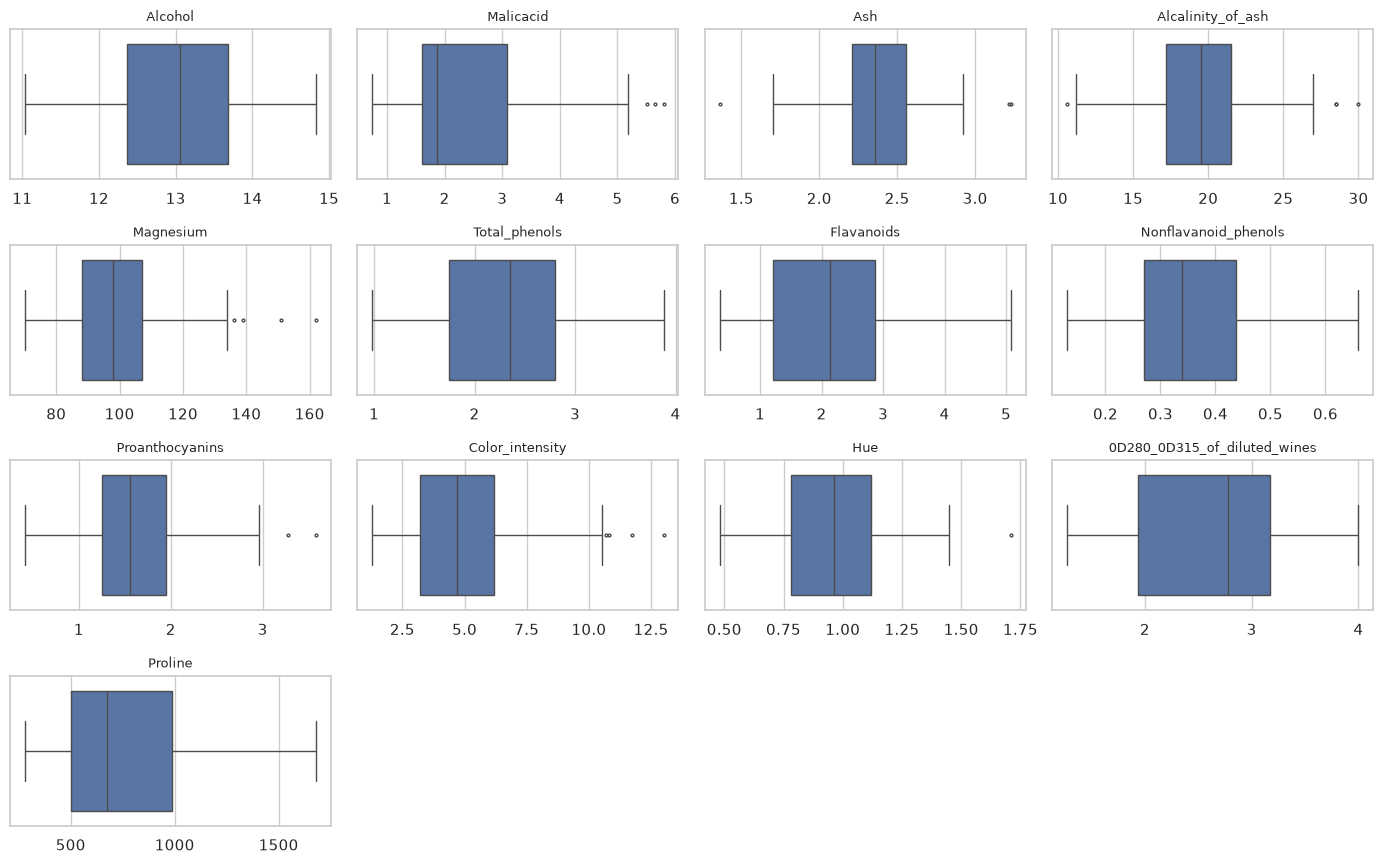

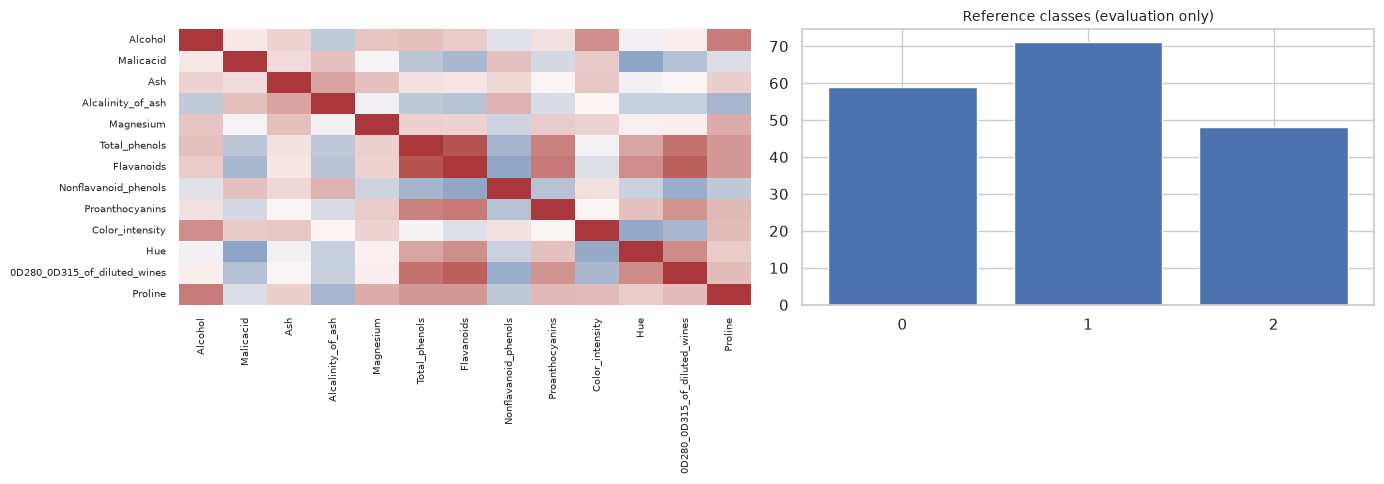

In [9]:
eda(real["wine"], store)

**10. Завантажуємо Seeds через бібліотеку або читаємо локальну копію.**

In [10]:
real["seeds"] = load_real("seeds", ROOT)
print(real["seeds"].frame.shape)

(210, 7)


**11. Переглядаємо Seeds: head, info, статистику, пропуски й дублікати.**

In [11]:
display(real["seeds"].frame.head())
print(frame_info(real["seeds"].frame))
display(real["seeds"].frame.describe().T)
display(real["seeds"].frame.isna().sum().to_frame("missing"))
print("Duplicate feature rows:", real["seeds"].frame.duplicated().sum())

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area           210 non-null    float64
 1   perimeter      210 non-null    float64
 2   compactness    210 non-null    float64
 3   kernel_length  210 non-null    float64
 4   kernel_width   210 non-null    float64
 5   asymmetry      210 non-null    float64
 6   groove_length  210 non-null    float64
dtypes: float64(7)
memory usage: 11.6 KB



,count,mean,std,min,25%,50%,75%,max
area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
kernel_length,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
kernel_width,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
asymmetry,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
groove_length,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500


,missing
area,0
perimeter,0
compactness,0
kernel_length,0
kernel_width,0
asymmetry,0
groove_length,0


Duplicate feature rows: 0


**12. Будуємо й зберігаємо гістограми, box plot, кореляції та розміри класів Seeds.**


seeds:
    area  perimeter  compactness  kernel_length  kernel_width  asymmetry  groove_length
0  15.26      14.84       0.8710          5.763         3.312      2.221          5.220
1  14.88      14.57       0.8811          5.554         3.333      1.018          4.956
2  14.29      14.09       0.9050          5.291         3.337      2.699          4.825
3  13.84      13.94       0.8955          5.324         3.379      2.259          4.805
4  16.14      14.99       0.9034          5.658         3.562      1.355          5.175
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area           210 non-null    float64
 1   perimeter      210 non-null    float64
 2   compactness    210 non-null    float64
 3   kernel_length  210 non-null    float64
 4   kernel_width   210 non-null    float64
 5   asymmetry      210 non-null    float64
 6   groove_length 

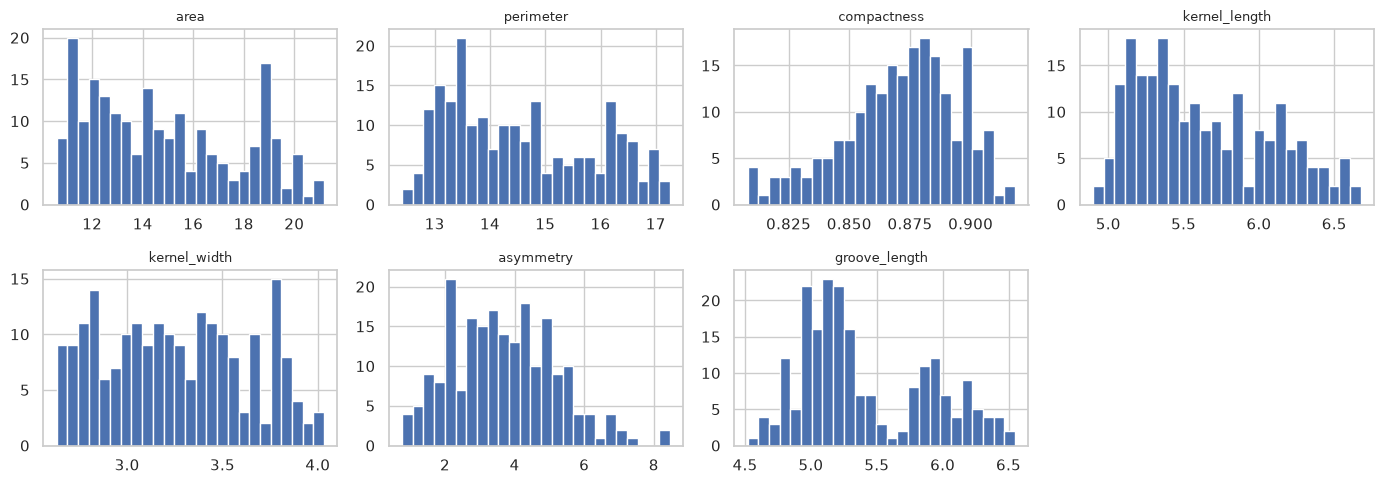

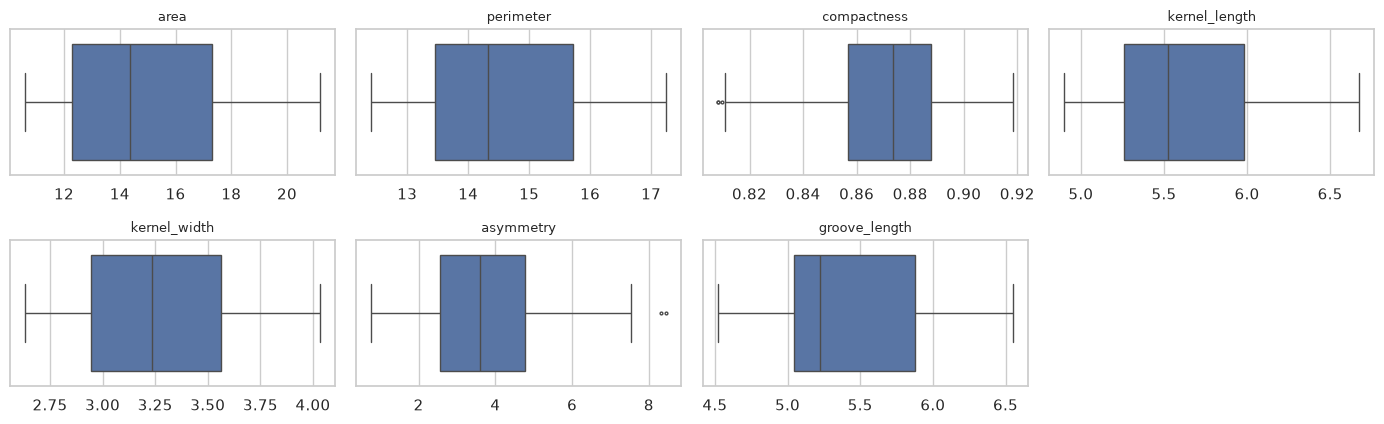

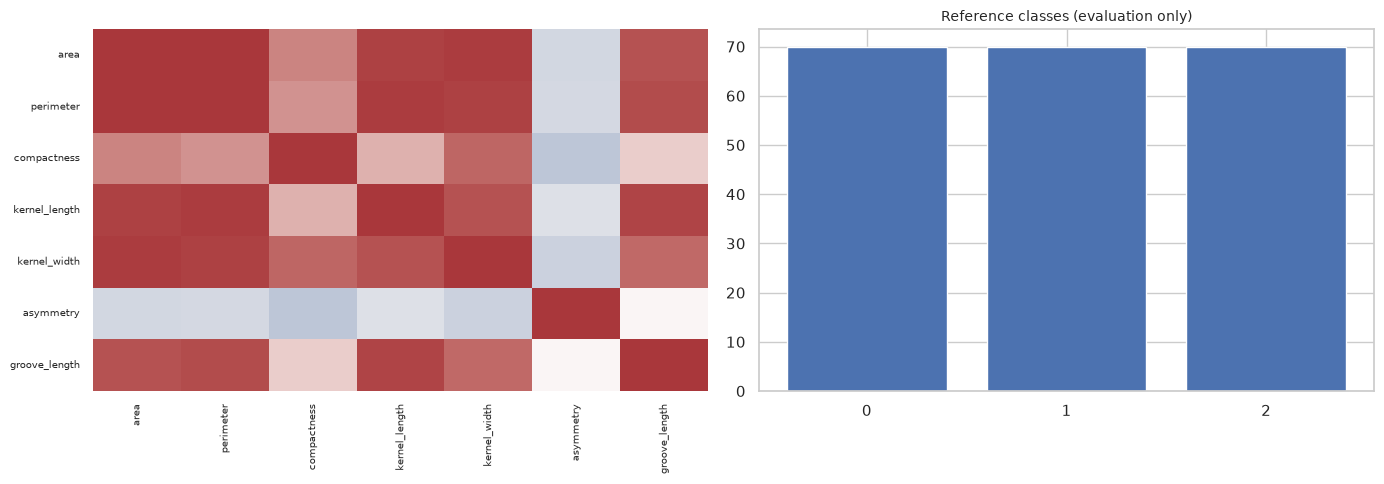

In [12]:
eda(real["seeds"], store)

**13. Завантажуємо Dry Bean через бібліотеку або читаємо локальну копію.**

In [13]:
real["dry_bean"] = load_real("dry_bean", ROOT)
print(real["dry_bean"].frame.shape)

(13611, 16)


**14. Переглядаємо Dry Bean: head, info, статистику, пропуски й дублікати.**

In [14]:
display(real["dry_bean"].frame.head())
print(frame_info(real["dry_bean"].frame))
display(real["dry_bean"].frame.describe().T)
display(real["dry_bean"].frame.isna().sum().to_frame("missing"))
print("Duplicate feature rows:", real["dry_bean"].frame.duplicated().sum())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
dtypes: float64(14), int64(2)
memory usage: 1.7 MB



,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860154
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRatio,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


,missing
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRatio,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Duplicate feature rows: 68


**15. Будуємо й зберігаємо гістограми, box plot, кореляції та розміри класів Dry Bean.**


dry_bean:
    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRatio  Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  Roundness  Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4
0  28395    610.291       208.178117       173.888747     1.197191      0.549812       28715     190.141097  0.763923  0.988856   0.958027     0.913358      0.007332      0.003147      0.834222      0.998724
1  28734    638.018       200.524796       182.734419     1.097356      0.411785       29172     191.272751  0.783968  0.984986   0.887034     0.953861      0.006979      0.003564      0.909851      0.998430
2  29380    624.110       212.826130       175.931143     1.209713      0.562727       29690     193.410904  0.778113  0.989559   0.947849     0.908774      0.007244      0.003048      0.825871      0.999066
3  30008    645.884       210.557999       182.516516     1.153638      0.498616       30724     195.467062  0.782681  0.976696   0.903936     0.928329      

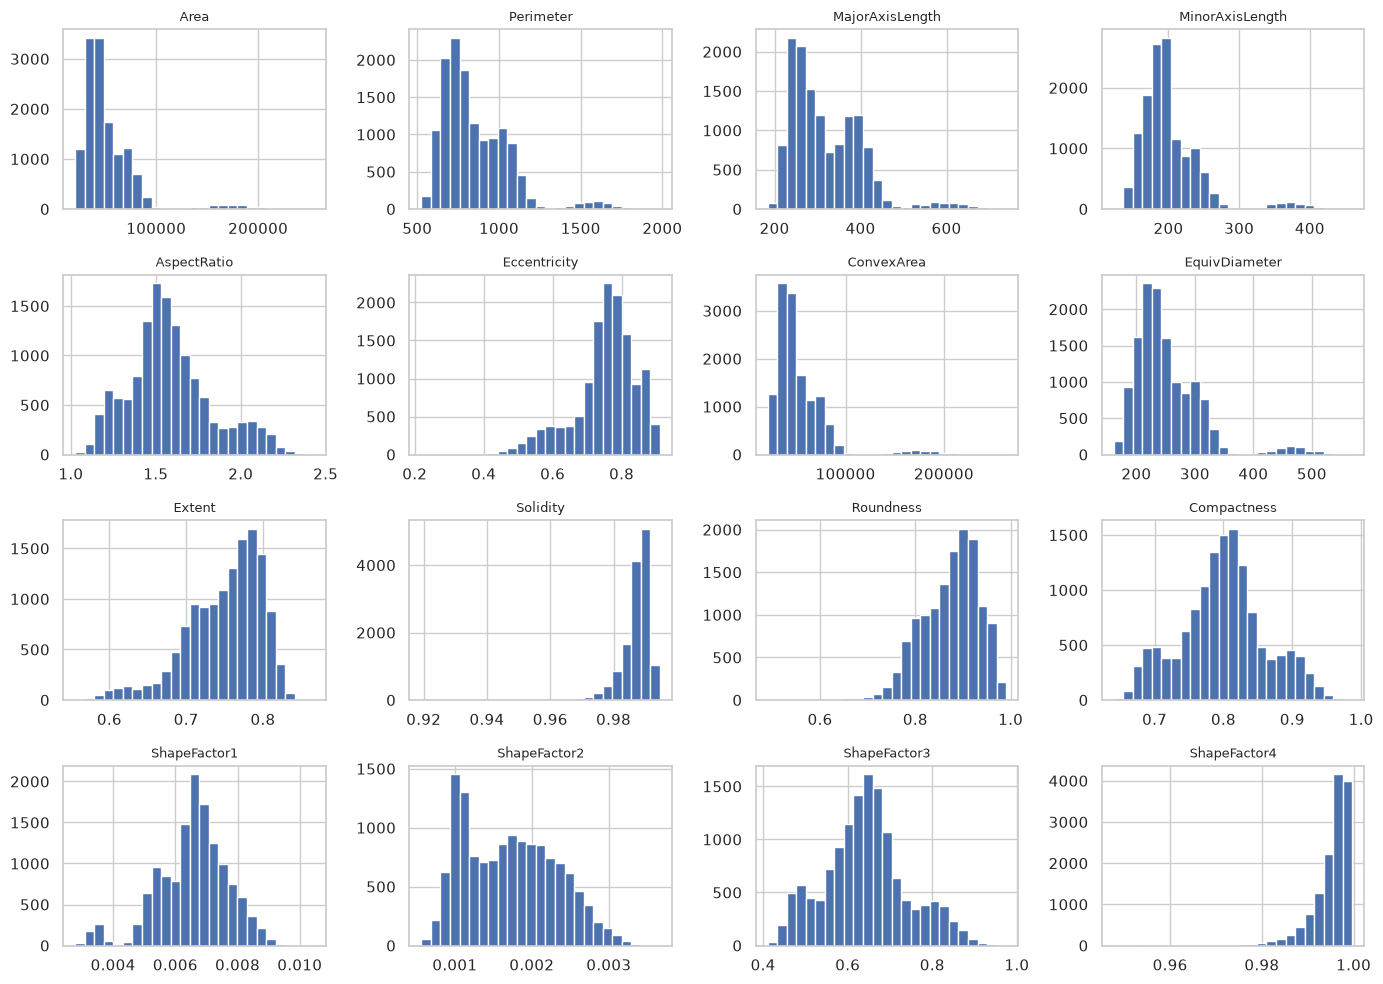

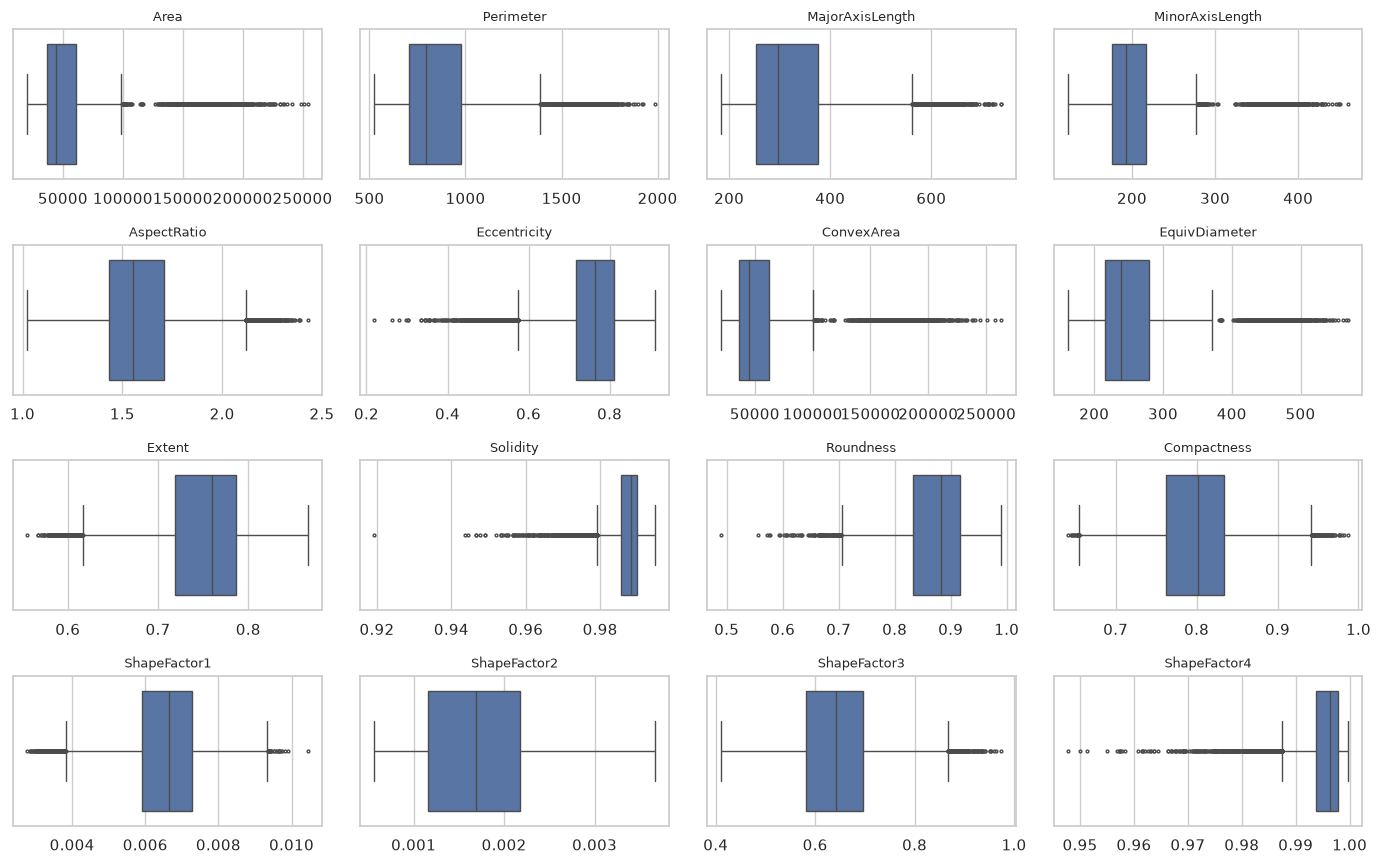

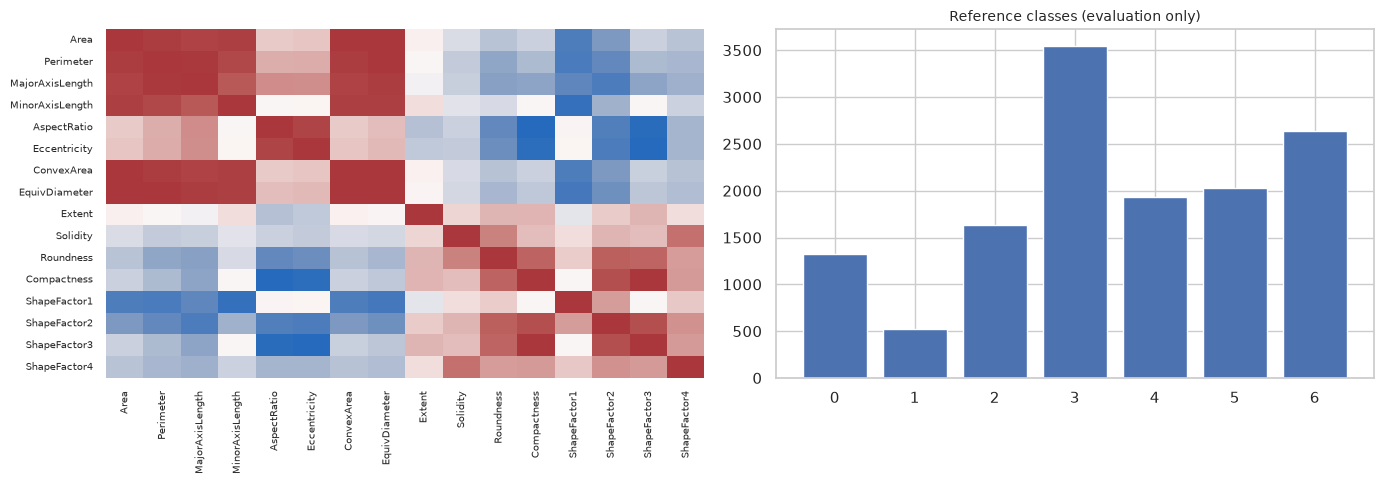

In [15]:
eda(real["dry_bean"], store)

**16. Фіксуємо синтетичні сценарії та параметри генерації.**
Детерміновані точки будуються з регулярної параметричної сітки; випадкові —
з PCG64 і MT19937. Наповнення дисків рівномірне за площею.

In [ ]:
from src.data import SHAPES

store.json(
    "config/synthetic.json",
    {
        "shapes": SHAPES,
        "mode": MODE,
        "seed": SEED,
        "n_per_cluster": 70 if MODE == "quick" else 100,
        "mixture_background_points": 18,
    },
)
print(SHAPES)

('circles', 'ellipses_parallel', 'ellipses_rotated', 'rectangles', 'rings', 'letters', 'mixture')


**17. Генеруємо й локально зберігаємо детерміновані геометричні набори.**

In [ ]:
synthetic = generate_suite(ROOT, MODE, SEED)
deterministic = {
    n: ds for n, ds in synthetic.items() if ds.meta["generator"] == "deterministic"
}
display(
    pd.DataFrame(
        [{"dataset": n, "n": len(ds.frame)} for n, ds in deterministic.items()]
    )
)

,dataset,n
0,circles_deterministic,300
1,ellipses_parallel_deterministic,300
2,ellipses_rotated_deterministic,300
3,rectangles_deterministic,300
4,rings_deterministic,300
5,letters_deterministic,300
6,mixture_deterministic,318


**18. Перевіряємо стохастичні версії та використані випадкові генератори.**

In [ ]:
stochastic = {
    n: ds for n, ds in synthetic.items() if ds.meta["generator"] != "deterministic"
}
display(pd.DataFrame([{"dataset": n, **ds.meta} for n, ds in stochastic.items()]))

,dataset,kind,shape,generator,seed,n_per_cluster,background_points
0,circles_PCG64_42,synthetic,circles,PCG64,42,100,0
1,circles_MT19937_42,synthetic,circles,MT19937,42,100,0
2,circles_PCG64_43,synthetic,circles,PCG64,43,100,0
3,ellipses_parallel_PCG64_42,synthetic,ellipses_parallel,PCG64,42,100,0
4,ellipses_parallel_MT19937_42,synthetic,ellipses_parallel,MT19937,42,100,0
5,ellipses_parallel_PCG64_43,synthetic,ellipses_parallel,PCG64,43,100,0
6,ellipses_rotated_PCG64_42,synthetic,ellipses_rotated,PCG64,42,100,0
7,ellipses_rotated_MT19937_42,synthetic,ellipses_rotated,MT19937,42,100,0
8,ellipses_rotated_PCG64_43,synthetic,ellipses_rotated,PCG64,43,100,0
9,rectangles_PCG64_42,synthetic,rectangles,PCG64,42,100,0


**19. Перевіряємо суміші форм, нерівні розміри груп і фонові шумові точки.**

In [ ]:
mixtures = {n: ds for n, ds in synthetic.items() if ds.meta["shape"] == "mixture"}
display(
    pd.DataFrame(
        [
            {"dataset": n, "class": int(label), "count": int((ds.y == label).sum())}
            for n, ds in mixtures.items()
            for label in np.unique(ds.y)
        ]
    )
)

,dataset,class,count
0,mixture_deterministic,-1,18
1,mixture_deterministic,0,50
2,mixture_deterministic,1,100
3,mixture_deterministic,2,150
4,mixture_PCG64_42,-1,18
5,mixture_PCG64_42,0,50
6,mixture_PCG64_42,1,100
7,mixture_PCG64_42,2,150
8,mixture_MT19937_42,-1,18
9,mixture_MT19937_42,0,50


**20. Для кожного синтетичного набору перевіряємо head, info, статистику й зберігаємо EDA.**
Scatter plot показує форму; гістограми й box plot контролюють координатні розподіли та масштаб.

In [20]:
for name, ds in synthetic.items():
    assert len(ds.frame) == len(ds.y) and np.isfinite(ds.frame.to_numpy()).all()
    eda(ds, store, show=False)
print("EDA збережено для", len(synthetic), "синтетичних наборів")


circles_deterministic:
          x         y
0  0.148864  0.048369
1  0.257840  0.083777
2  0.332870  0.108156
3  0.393857  0.127972
4  0.446592  0.145106
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB




circles_PCG64_42:
          x         y
0 -0.570966  0.230729
1 -0.210609 -0.613479
2  0.212303 -0.032775
3  0.137203 -0.595091
4 -0.238475  0.076846
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB




circles_MT19937_42:
          x         y
0 -0.376405 -0.351989
1  0.063581 -0.155141
2 -0.451479 -0.466490
3 -0.261549 -0.515499
4 -0.046511 -0.483126
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB




circles_PCG64_43:
          x         y
0  0.544105  0.153547
1  0.052669 -0.083908
2  0.084889  0.529617
3 -0.052151  0.604697
4 -0.432337  0.137384
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB




ellipses_parallel_deterministic:
          x         y
0  0.297728  0.020729
1  0.515680  0.035905
2  0.665740  0.046353
3  0.787714  0.054845
4  0.893183  0.062188
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB




ellipses_parallel_PCG64_42:
          x         y
0 -1.141933  0.098884
1 -0.421219 -0.262920
2  0.424607 -0.014046
3  0.274407 -0.255039
4 -0.476950  0.032934
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    float64
 1   y       300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB



... (19 outputs left out)


mixture_PCG64_42:
          x         y
0 -0.367050  0.148326
1 -0.135392 -0.394379
2  0.136481 -0.021070
3  0.088202 -0.382559
4 -0.153305  0.049401
<class 'pandas.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       318 non-null    float64
 1   y       318 non-null    float64
dtypes: float64(2)
memory usage: 5.1 KB




mixture_MT19937_42:
          x         y
0 -0.241974 -0.226279
1  0.040874 -0.099733
2 -0.290236 -0.299886
3 -0.168139 -0.331392
4 -0.029900 -0.310581
<class 'pandas.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       318 non-null    float64
 1   y       318 non-null    float64
dtypes: float64(2)
memory usage: 5.1 KB




mixture_PCG64_43:
          x         y
0  0.349782  0.098709
1  0.033859 -0.053941
2  0.054571  0.340468
3 -0.033526  0.388734
4 -0.277931  0.088318
<class 'pandas.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       318 non-null    float64
 1   y       318 non-null    float64
dtypes: float64(2)
memory usage: 5.1 KB



EDA збережено для 28 синтетичних наборів


**21. Порівнюємо геометрію детермінованих і випадкових наборів.**

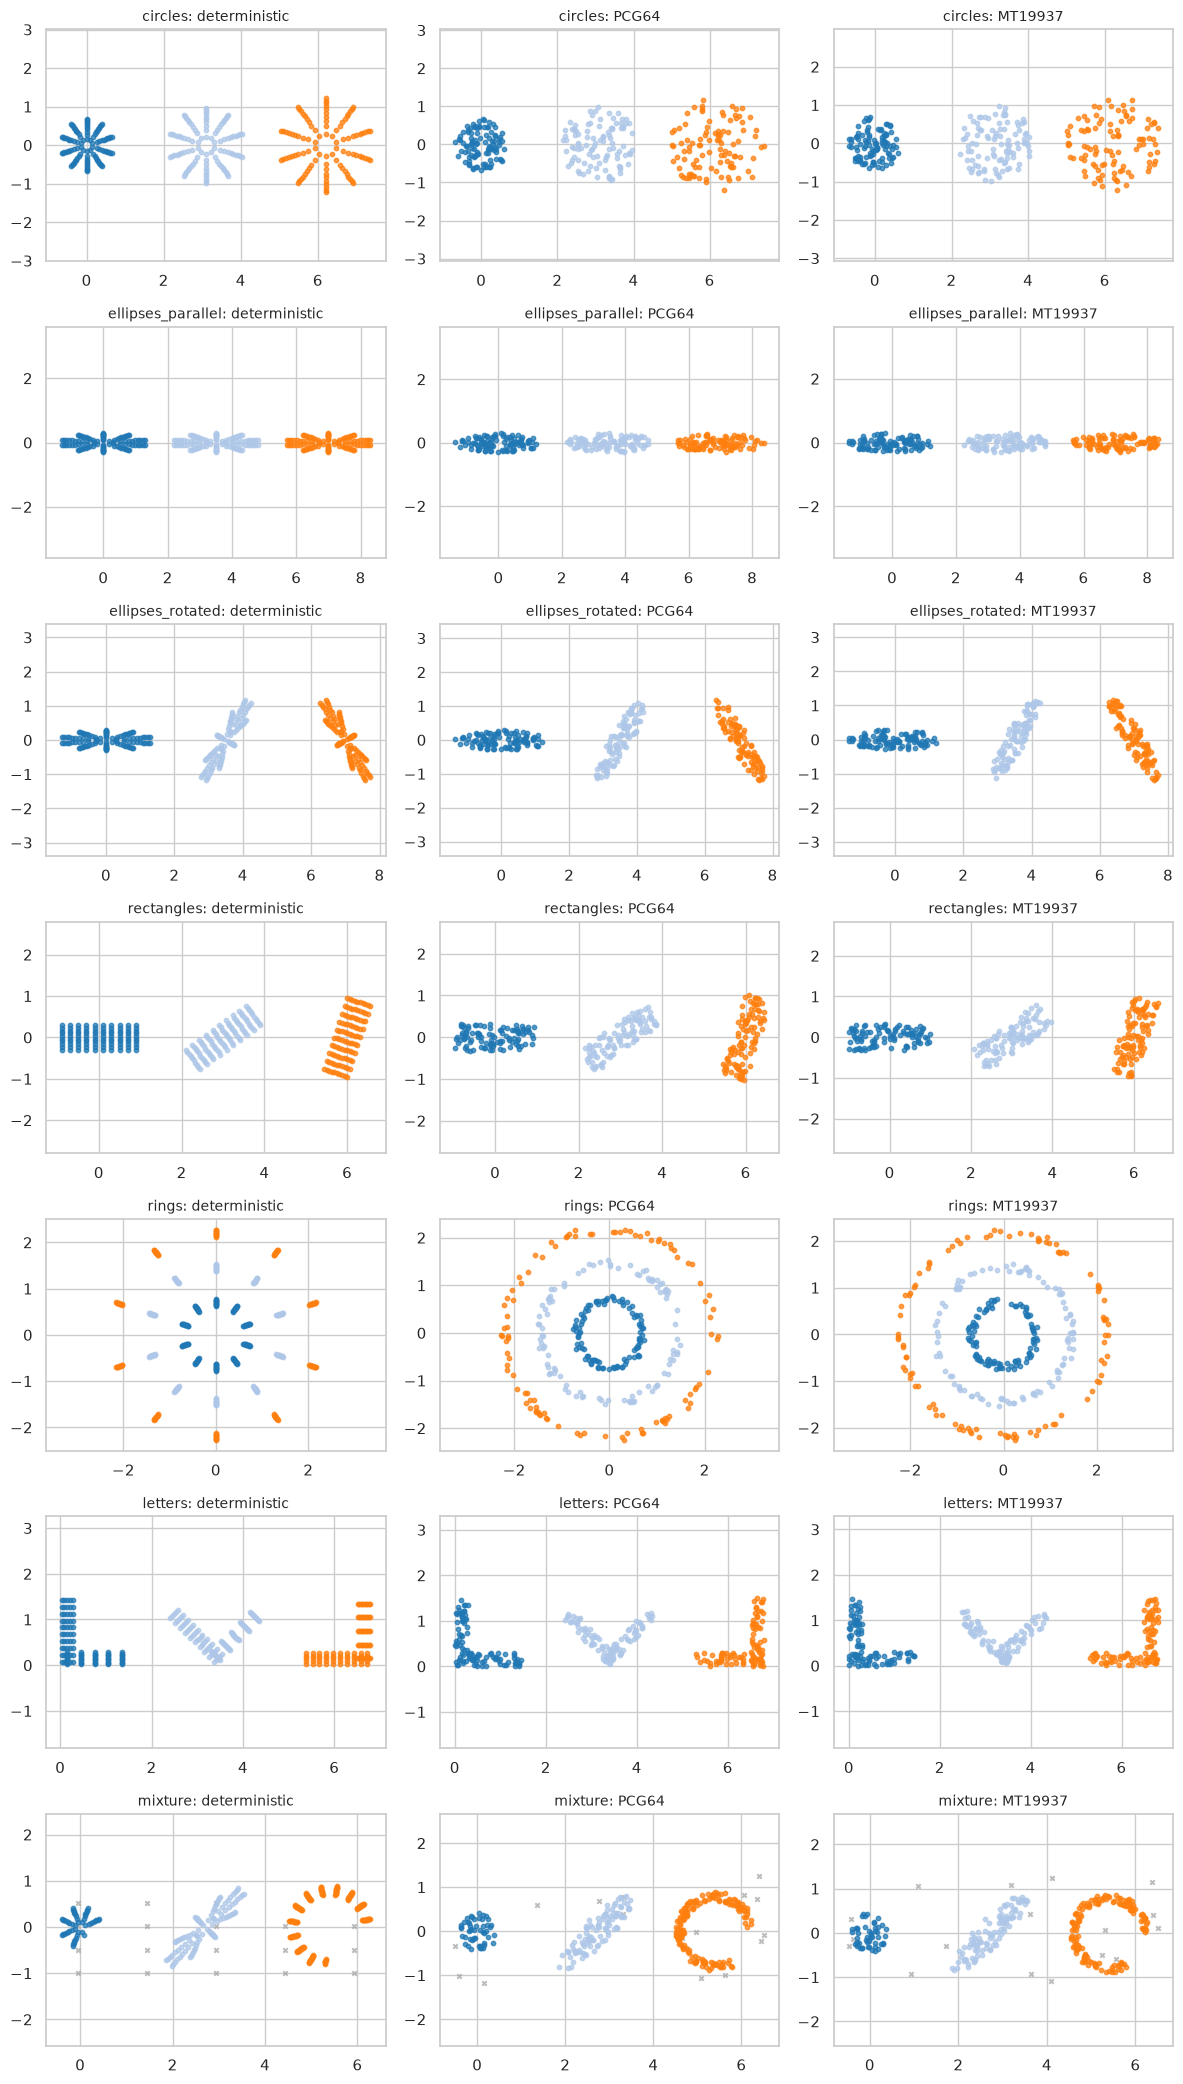

In [ ]:
fig, axes = plt.subplots(len(SHAPES), 3, figsize=(12, 3 * len(SHAPES)))
for row, shape in enumerate(SHAPES):
    for col, generator in enumerate(("deterministic", "PCG64", "MT19937")):
        ds = next(
            ds
            for ds in synthetic.values()
            if ds.meta["shape"] == shape
            and ds.meta["generator"] == generator
            and ds.meta["seed"] in (None, SEED)
        )
        scatter(axes[row, col], ds.frame.to_numpy(), ds.y, f"{shape}: {generator}")
fig.tight_layout()
store.figure("synthetic/geometry_overview", fig)

**22. Фіксуємо правила підготовки: числові ознаки, медіанна імпутація й масштабування.**
Мітки не входять до матриці ознак. Викиди й дублікати не видаляємо автоматично.
Для синтетики спільний масштаб координат зберігає форму фігур.

In [ ]:
store.json(
    "config/preprocessing.json",
    {
        "real": "median imputation, standard scaling per feature",
        "synthetic": "centering, common RMS standard deviation across axes",
        "duplicates": "retained",
        "outliers": "retained",
        "targets": "evaluation only",
        "sampling": "fixed stratified subset; reference classes used only to preserve sampling proportions",
        "sample_cap": MAX_SAMPLES,
    },
)

**23. Готуємо дані та зберігаємо індекси вибірок і параметри перетворень.**

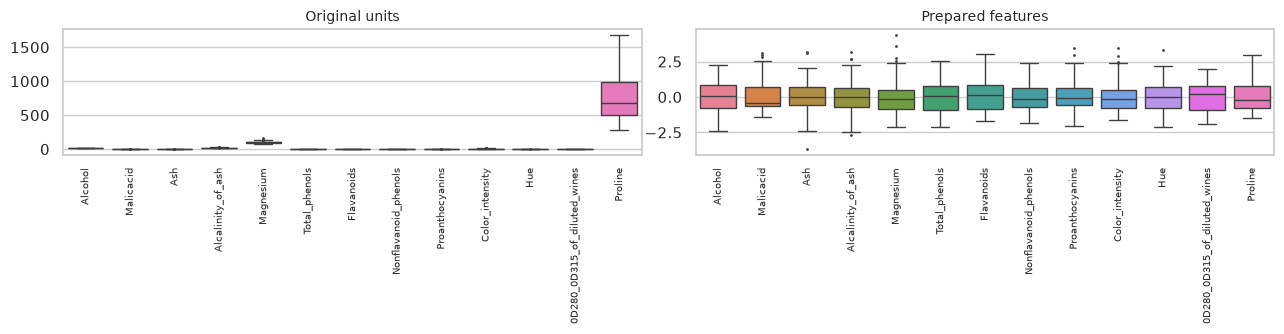

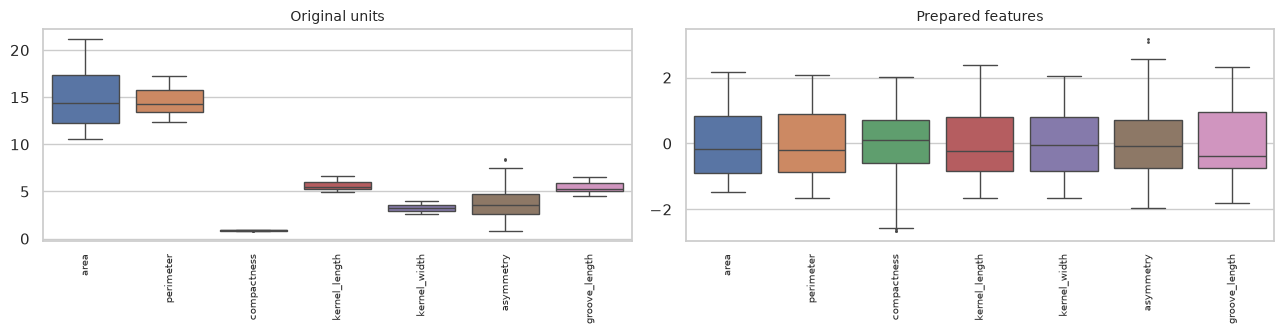

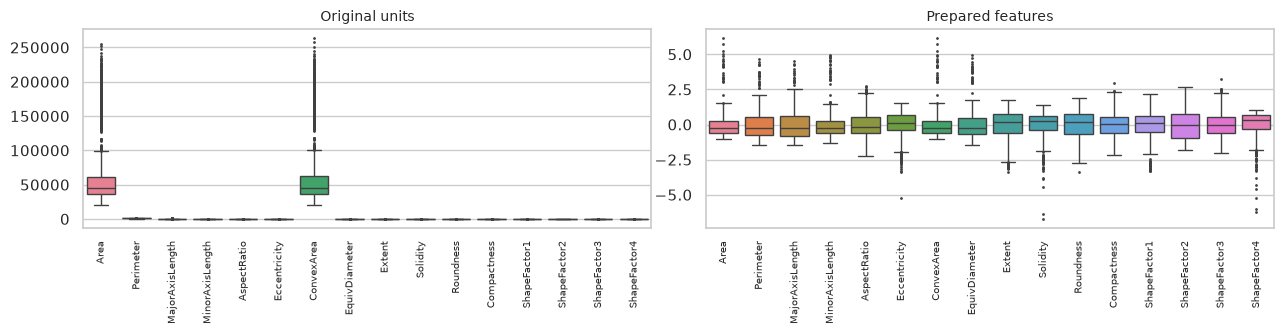

In [ ]:
records = {
    name: prepare(ds, MAX_SAMPLES, SEED, store)
    for name, ds in {**synthetic, **real}.items()
}
for name, ds in real.items():
    preprocessing_plot(ds, records[name], store)

**24. Будуємо PCA-представлення реальних даних для спільного 2D-експерименту.**
Це окремий експеримент, а не лише малюнок повновимірної кластеризації.

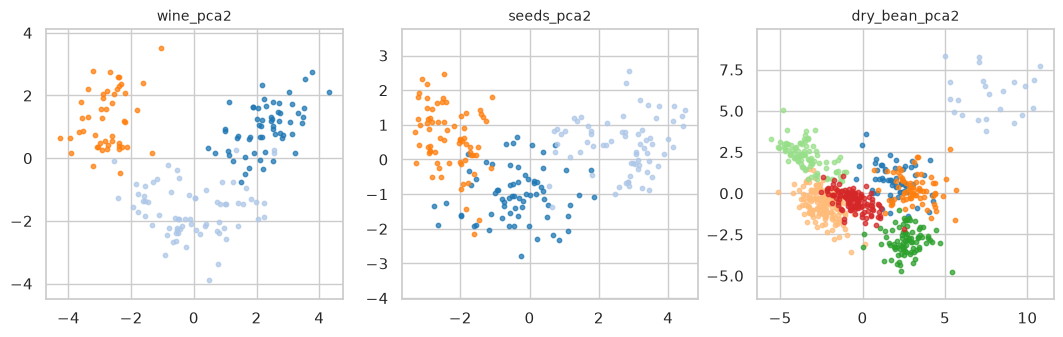

In [24]:
pca_records = {name + "_pca2": pca_record(records[name], store) for name in real}
records.update(pca_records)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, record) in zip(axes, pca_records.items()):
    scatter(ax, record["X"], record["y"], name)
store.figure("preprocessing/real_pca", fig)

**25. Формуємо реєстр однакових вхідних даних для алгоритмів і окреме джерело ресурсних тестів.**

In [ ]:
registry = pd.DataFrame(
    [
        {
            "dataset": name,
            "n": len(r["X"]),
            "d": r["X"].shape[1],
            "kind": r["kind"],
            "representation": r["representation"],
        }
        for name, r in records.items()
    ]
)
store.table("config/dataset_registry", registry)
display(registry)
benchmark_ds = Dataset(
    "dry_bean_benchmark",
    real["dry_bean"].frame,
    real["dry_bean"].y,
    real["dry_bean"].meta,
)
benchmark_full = prepare(benchmark_ds, len(benchmark_ds.frame), SEED, store)
benchmark_records = {"dry_bean_pca2": pca_record(benchmark_full, store)}

,dataset,n,d,kind,representation
0,circles_deterministic,300,2,synthetic,original_scaled
1,circles_PCG64_42,300,2,synthetic,original_scaled
2,circles_MT19937_42,300,2,synthetic,original_scaled
3,circles_PCG64_43,300,2,synthetic,original_scaled
4,ellipses_parallel_deterministic,300,2,synthetic,original_scaled
5,ellipses_parallel_PCG64_42,300,2,synthetic,original_scaled
6,ellipses_parallel_MT19937_42,300,2,synthetic,original_scaled
7,ellipses_parallel_PCG64_43,300,2,synthetic,original_scaled
8,ellipses_rotated_deterministic,300,2,synthetic,original_scaled
9,ellipses_rotated_PCG64_42,300,2,synthetic,original_scaled


**26. Визначаємо спільний інтерфейс і контрольний набір для перевірки методів.**

In [ ]:
control_X, control_y = make_blobs(
    n_samples=90,
    centers=[[-4, -3], [0, 4], [4, -3]],
    cluster_std=0.2,
    random_state=SEED,
)
controls = {}
print("Algorithms:", ALGORITHMS)

Algorithms: ('PAM', 'WaveCluster', 'GMM', 'MCL')


**27. Перевіряємо оригінальний PAM, його медоїди та функцію втрат.**

In [27]:
controls["PAM"] = run_algorithm("PAM", control_X)
print(controls["PAM"].diagnostics)

{'loss': 21.348029870413438, 'iterations': 2, 'implementation': 'kmedoids.pam (original PAM, not FasterPAM)'}


**28. Перевіряємо збіжність GMM і нормування ймовірностей належності.**

In [28]:
controls["GMM"] = run_algorithm("GMM", control_X)
assert np.allclose(controls["GMM"].arrays["probabilities"].sum(axis=1), 1)
print(controls["GMM"].diagnostics)

{'converged': True, 'iterations': 2, 'bic': 179.20776046593951, 'aic': 136.710996070325, 'lower_bound': -0.570616644835139, 'warnings': []}


**29. Перевіряємо граф MCL і збіжність потокової матриці.**
Для контрольного прикладу inflation=1.5; інші значення можуть дробити навіть компактні групи.

In [29]:
control_mcl_params = {**default_params("MCL", control_X), "inflation": 1.5}
controls["MCL"] = run_algorithm("MCL", control_X, control_mcl_params)
assert np.allclose(np.asarray(controls["MCL"].matrices["flow"].sum(axis=0)), 1)
print(controls["MCL"].diagnostics)

{'iterations': 15, 'residual': 0.0, 'converged': True, 'sigma': 0.17985500455292297, 'graph_nnz': 1234, 'graph': 'symmetric union kNN, Gaussian weights, unit loops', 'extraction': 'unique attractor supports, maximum-flow overlap resolution'}


**30. Перевіряємо WaveCluster: квантування, Haar DWT, значущі комірки та зв’язні компоненти.**
Поріг відносний до максимуму густини; зв’язність — 8; малі компоненти стають шумом.
Децимована Haar-сітка чутлива до вирівнювання; її межі зберігаємо явно.

In [ ]:
controls["WaveCluster"] = run_algorithm("WaveCluster", control_X)
print(controls["WaveCluster"].diagnostics)
store.json(
    "config/wavecluster_variant.json",
    {
        "name": "WaveCluster/Haar-DWT-2D",
        "wavelet": "haar",
        "transform": "decimated DWT",
        "boundary_mode": "zero",
        "significance": "relative to max approximation density",
        "connectivity": 8,
        "mapping": "fine bin indices // 2**level",
        "limitation": "not an exact reproduction of the original paper's filter settings; 2D only",
    },
)

{'implementation': 'WaveCluster/Haar-DWT-2D (explicit research variant)', 'wavelet': 'haar', 'boundary_mode': 'zero', 'connectivity': 8, 'cutoff': 0.44000000000000006, 'components_before_filter': 3, 'out_of_bounds': 0}


**31. Перевіряємо відтворюваність і правильність роботи всіх методів на контрольному прикладі.**

In [ ]:
control_scores = []
for algorithm, result in controls.items():
    params = (
        control_mcl_params
        if algorithm == "MCL"
        else default_params(algorithm, control_X)
    )
    repeat = run_algorithm(algorithm, control_X, params, SEED)
    assert np.array_equal(result.labels, repeat.labels)
    ari = adjusted_rand_score(control_y, result.labels)
    assert ari > 0.9, (algorithm, ari)
    control_scores.append({"algorithm": algorithm, "ari": ari})
store.table("metrics/control_checks", pd.DataFrame(control_scores))
display(pd.DataFrame(control_scores))

,algorithm,ari
0,PAM,1.000000
1,GMM,1.000000
2,MCL,1.000000
3,WaveCluster,0.967817


**32. Фіксуємо метрики й правила вибору параметрів без оптимізації за еталонними мітками.**
GMM: мінімальний BIC. Решта: silhouette за coverage≥0.8 та 2–20 кластерами.
Якщо допустимої конфігурації немає, fallback явно записується в артефактах.
Цей критерій схильний до компактних груп; ARI/AMI використовуються лише після вибору.

In [ ]:
store.json(
    "config/metrics.json",
    {
        "external": ["ARI all", "AMI all", "ARI covered", "AMI covered"],
        "internal": [
            "silhouette (up to 600 samples)",
            "Davies-Bouldin",
            "Calinski-Harabasz",
        ],
        "noise": "exclude from internal scores, retain coverage and all-point external scores",
        "undefined": "NaN with reason; never substitute a fictitious zero",
        "selection": CONFIG["selection"],
    },
)

**33. Виконуємо коротку перевірку збереження результатів на одному наборі.**

In [ ]:
smoke_name = "circles_deterministic"
smoke_selected = {
    (smoke_name, algorithm): default_params(algorithm, records[smoke_name]["X"])
    for algorithm in ALGORITHMS
}
smoke_metrics, smoke_outputs = evaluate(
    {smoke_name: records[smoke_name]}, smoke_selected, store, SEED
)
assert (smoke_metrics.status == "ok").all()
store.table("metrics/smoke", smoke_metrics)
display(smoke_metrics[["algorithm", "status", "n_clusters", "ari_all"]])

,algorithm,status,n_clusters,ari_all
0,PAM,ok,3,1.000000
1,WaveCluster,ok,2,0.569784
2,GMM,ok,3,1.000000
3,MCL,ok,32,0.112049


**34. Досліджуємо параметри на кожному наборі та зберігаємо обрані конфігурації.**
Повновимірні набори для 2D WaveCluster пропускаються з явною причиною.

In [ ]:
selected, parameter_search = tune(records, store, MODE, SEED)
display(
    parameter_search.groupby(["algorithm", "status"])
    .size()
    .rename("runs")
    .reset_index()
)

,algorithm,status,runs
0,GMM,ok,340
1,MCL,ok,204
2,PAM,ok,170
3,WaveCluster,ok,186
4,WaveCluster,skipped,3


**35. Порівнюємо алгоритми на детермінованих геометричних наборах.**

In [35]:
det_records = {n: records[n] for n in deterministic}
det_metrics, det_outputs = evaluate(det_records, selected, store, SEED)
store.table("metrics/deterministic", det_metrics)
display(det_metrics[["dataset", "algorithm", "status", "ari_all", "coverage"]])

,dataset,algorithm,status,ari_all,coverage
0,circles_deterministic,PAM,ok,1.000000,1.000000
1,circles_deterministic,WaveCluster,ok,0.949057,0.966667
2,circles_deterministic,GMM,ok,1.000000,1.000000
3,circles_deterministic,MCL,ok,0.117994,1.000000
4,ellipses_parallel_deterministic,PAM,ok,1.000000,1.000000
5,ellipses_parallel_deterministic,WaveCluster,ok,0.985279,0.990000
6,ellipses_parallel_deterministic,GMM,ok,0.554816,1.000000
7,ellipses_parallel_deterministic,MCL,ok,0.232516,1.000000
8,ellipses_rotated_deterministic,PAM,ok,1.000000,1.000000
9,ellipses_rotated_deterministic,WaveCluster,ok,0.915358,0.943333


**36. Порівнюємо алгоритми на стохастичних наборах і різних випадкових генераторах.**

In [ ]:
random_records = {n: records[n] for n in stochastic}
random_metrics, random_outputs = evaluate(random_records, selected, store, SEED)
store.table("metrics/stochastic", random_metrics)
display(
    random_metrics.groupby("algorithm")[["ari_all", "coverage"]].agg(["mean", "std"])
)

ari_all            coverage          
                 mean       std      mean       std
algorithm                                          
GMM          0.741534  0.339535  1.000000  0.000000
MCL          0.247120  0.091396  1.000000  0.000000
PAM          0.862716  0.309727  1.000000  0.000000
WaveCluster  0.806533  0.242926  0.946277  0.034559

**37. Порівнюємо алгоритми на реальних ознаках і спільних PCA-представленнях окремо.**

In [37]:
real_records = {n: r for n, r in records.items() if r["kind"] == "real"}
real_metrics, real_outputs = evaluate(real_records, selected, store, SEED)
store.table("metrics/real", real_metrics)
display(real_metrics[["dataset", "algorithm", "status", "ari_all", "coverage"]])

,dataset,algorithm,status,ari_all,coverage
0,wine,PAM,ok,0.741137,1.000000
1,wine,WaveCluster,skipped,NaN,NaN
2,wine,GMM,ok,0.688399,1.000000
3,wine,MCL,ok,0.804079,1.000000
4,seeds,PAM,ok,0.444043,1.000000
5,seeds,WaveCluster,skipped,NaN,NaN
6,seeds,GMM,ok,0.609609,1.000000
7,seeds,MCL,ok,0.537574,1.000000
8,dry_bean,PAM,ok,0.279574,1.000000
9,dry_bean,WaveCluster,skipped,NaN,NaN


**38. Об’єднуємо результати якості й перевіряємо причини пропущених або невдалих запусків.**

In [ ]:
metrics = pd.concat([det_metrics, random_metrics, real_metrics], ignore_index=True)
outputs = {**det_outputs, **random_outputs, **real_outputs}
store.table("metrics/all_results", metrics)
display(metrics.groupby(["algorithm", "status"]).size().rename("runs").reset_index())
display(
    metrics.loc[metrics.status != "ok", ["dataset", "algorithm", "status", "reason"]]
)

,algorithm,status,runs
0,GMM,ok,34
1,MCL,ok,34
2,PAM,ok,34
3,WaveCluster,ok,31
4,WaveCluster,skipped,3


,dataset,algorithm,status,reason
113,wine,WaveCluster,skipped,No selected configuration (see parameter search)
117,seeds,WaveCluster,skipped,No selected configuration (see parameter search)
121,dry_bean,WaveCluster,skipped,No selected configuration (see parameter search)


**39. Зберігаємо порівняльні візуалізації розбиттів для кожного набору.**
Для повновимірних результатів PCA тут використовується лише для відображення.

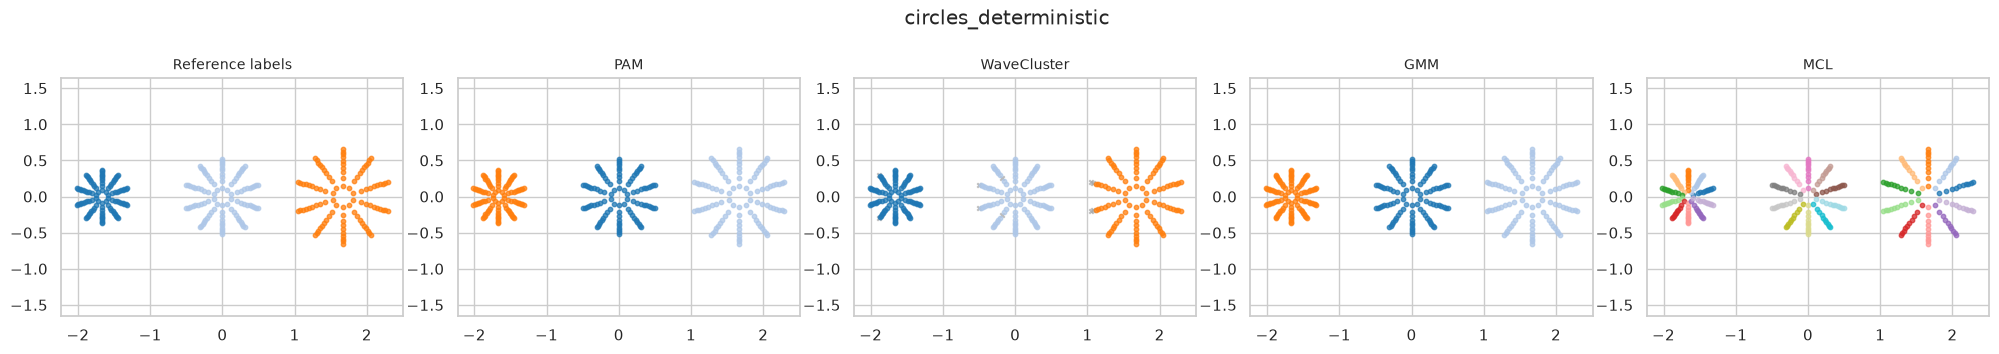

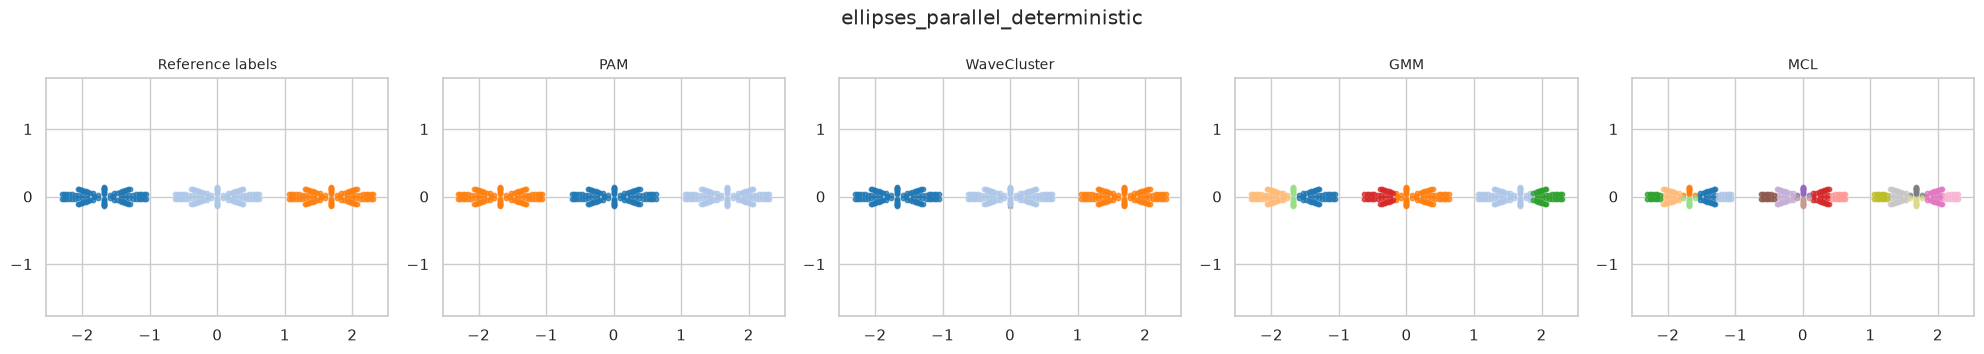

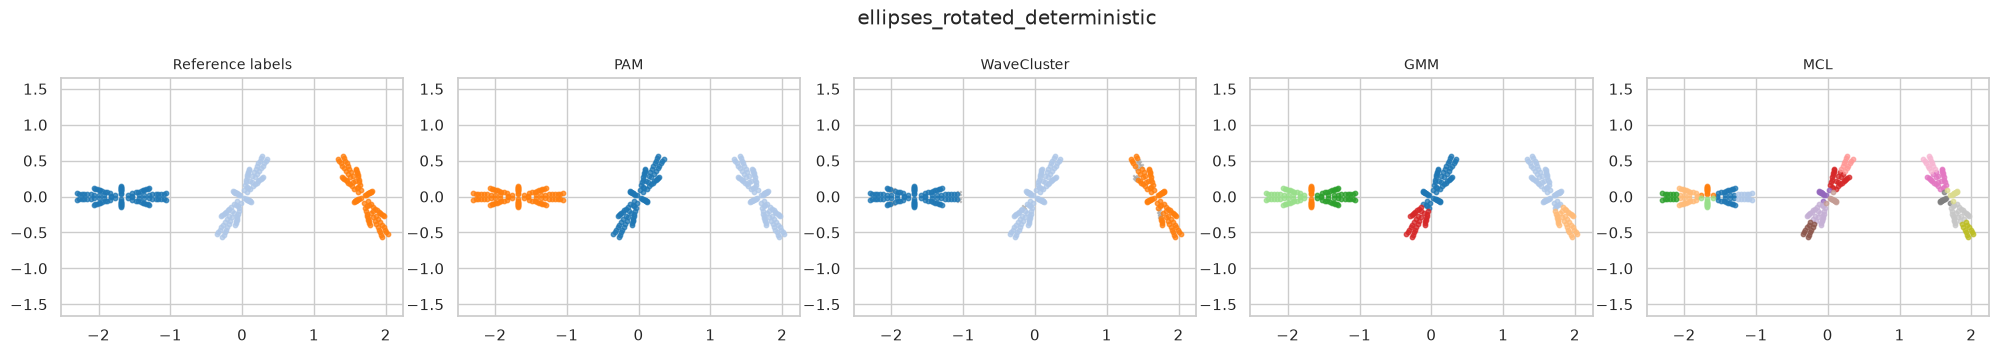

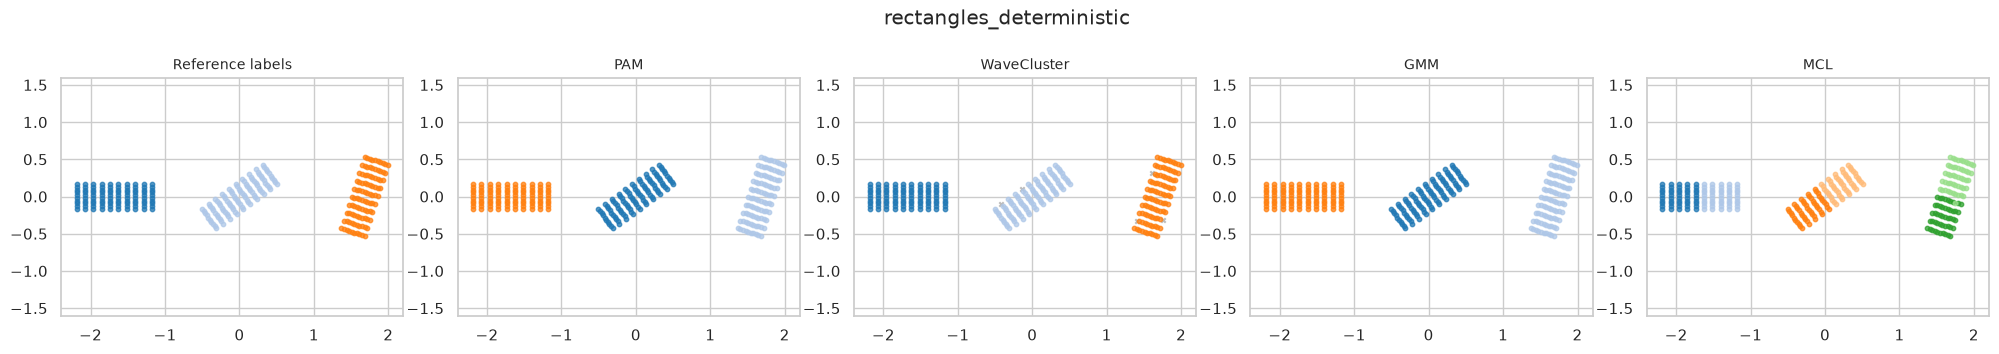

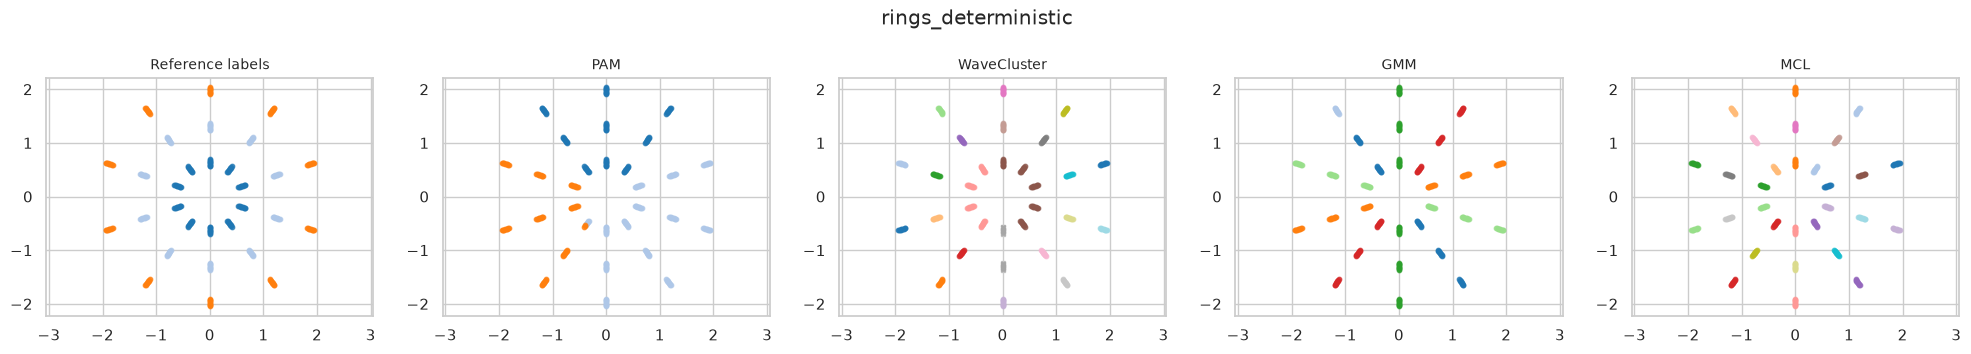

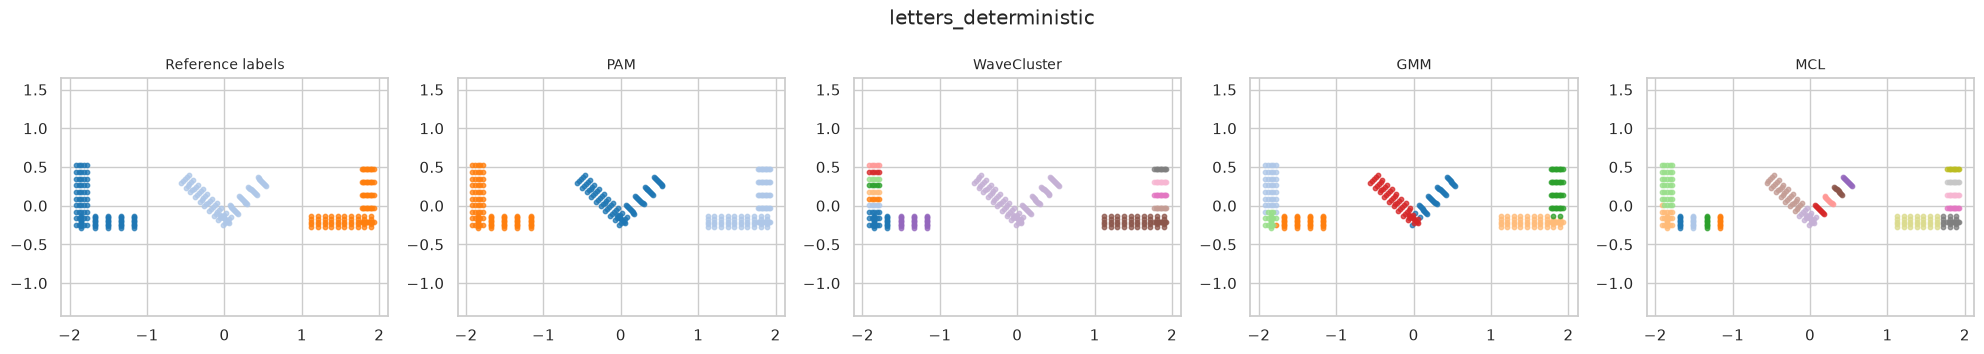

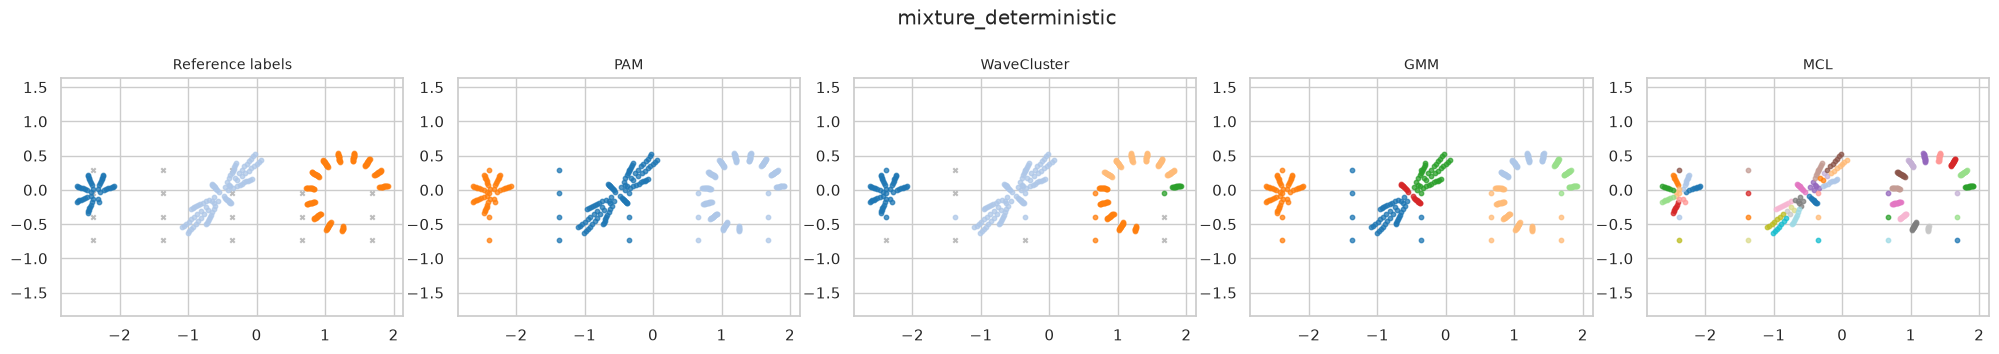

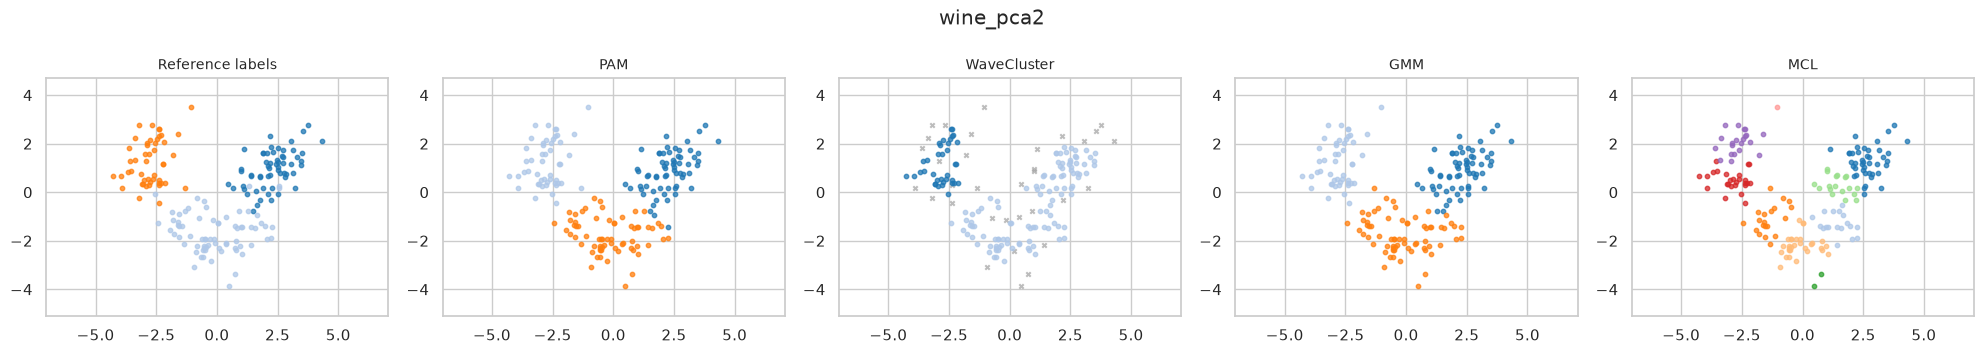

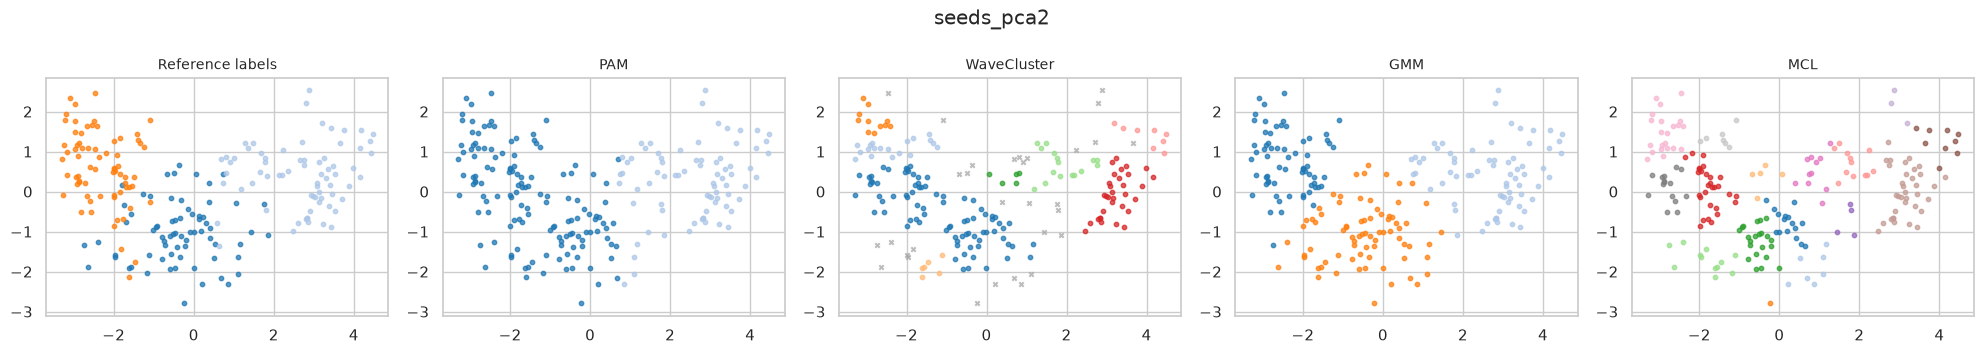

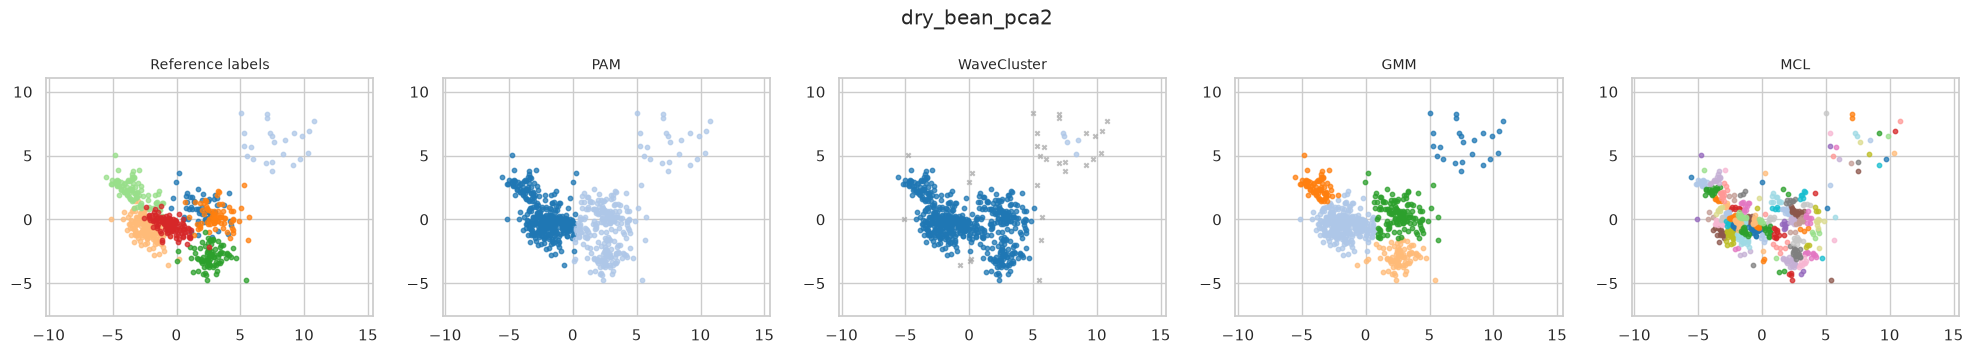

In [ ]:
for name, result_group in outputs.items():
    if result_group:
        compare(
            records[name],
            result_group,
            store,
            show=name.endswith("deterministic") or name in pca_records,
        )

**40. Показуємо медоїди PAM та гаусівські компоненти й невизначеність GMM.**

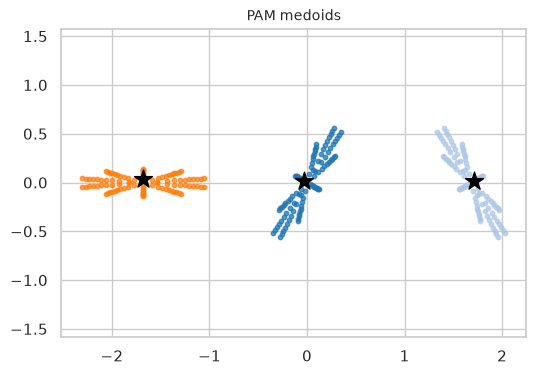

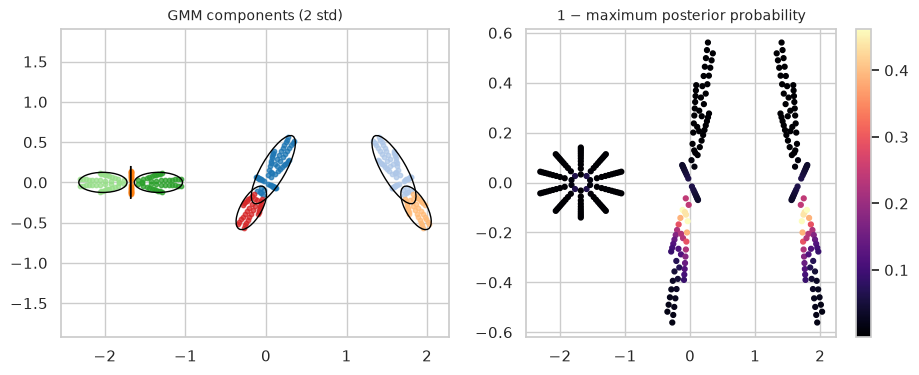

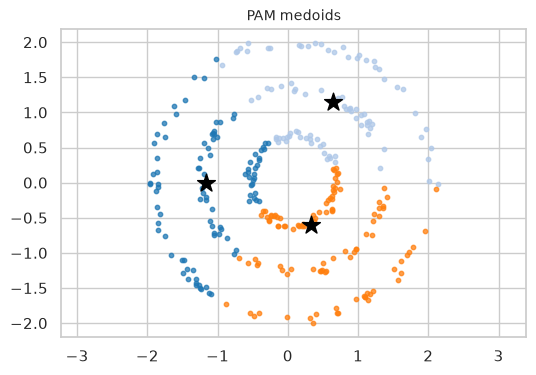

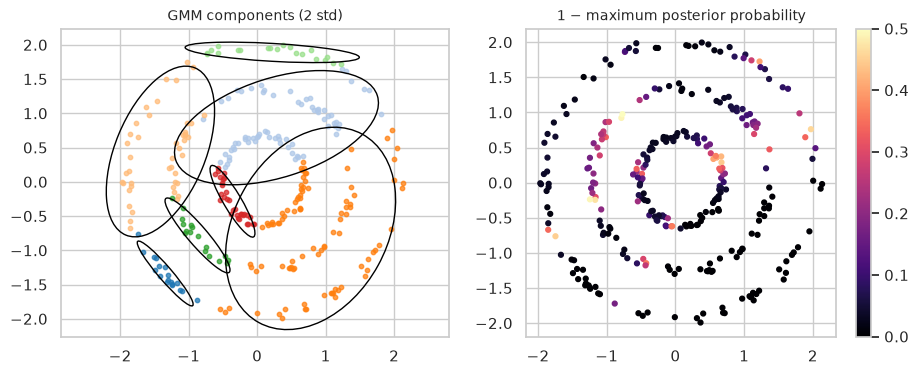

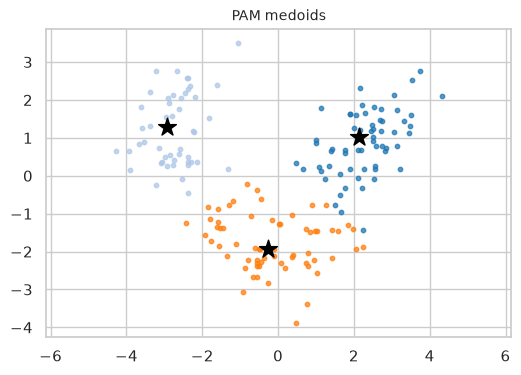

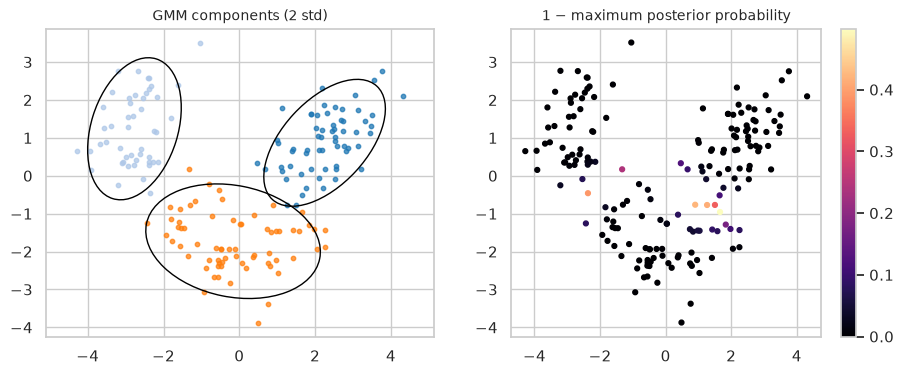

In [40]:
illustrative_names = ["ellipses_rotated_deterministic", "rings_PCG64_42", "wine_pca2"]
for name in illustrative_names:
    subset = {a: r for a, r in outputs[name].items() if a in {"PAM", "GMM"}}
    intermediates(records[name], subset, store)

**41. Показуємо граф і збіжність MCL та проміжні сітки WaveCluster.**

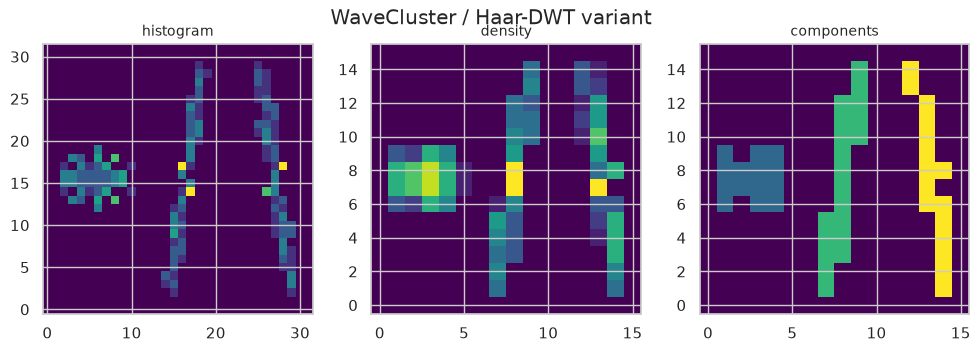

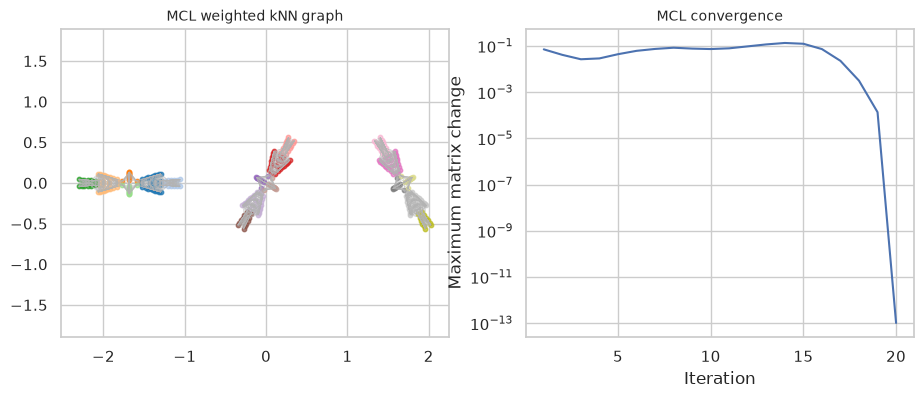

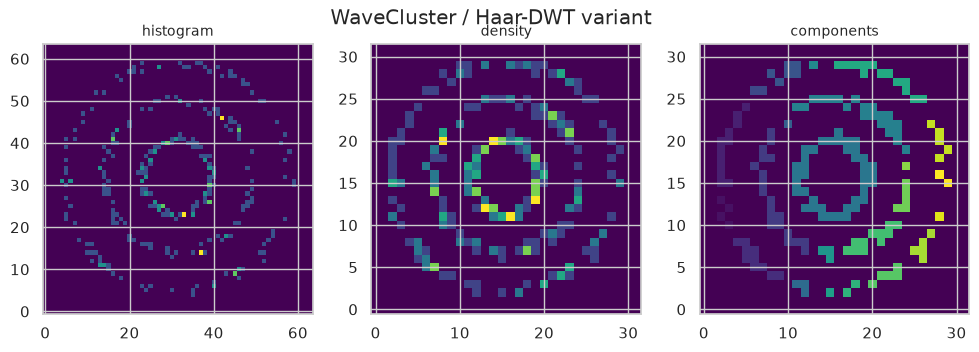

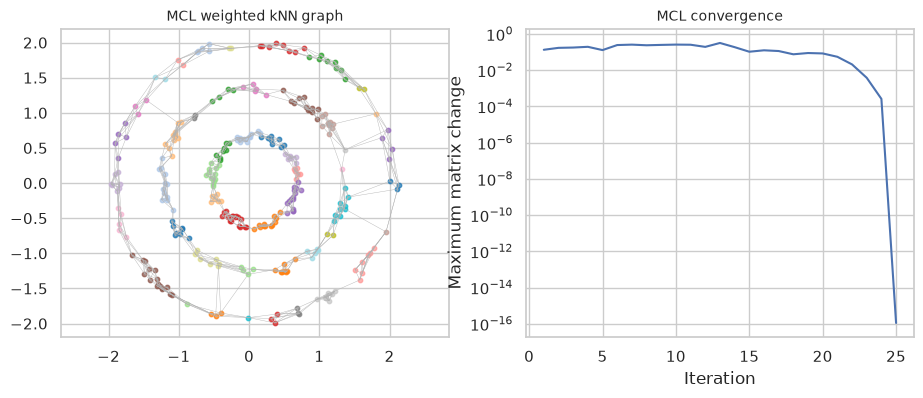

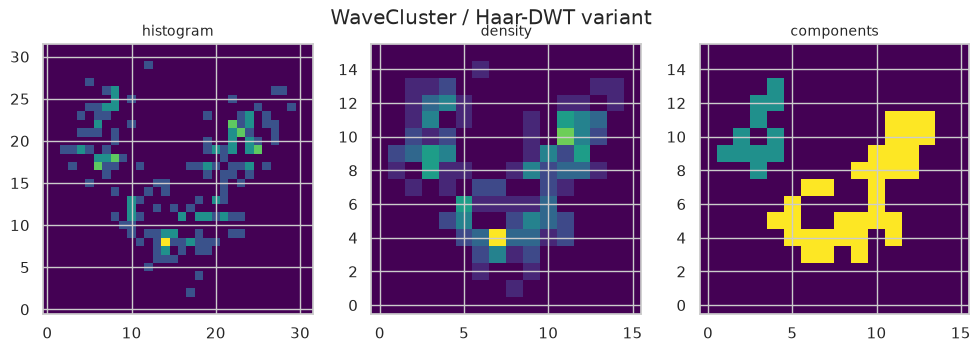

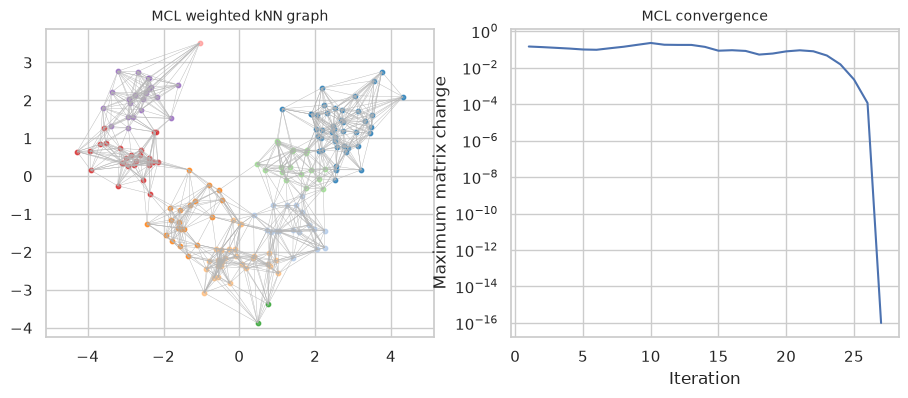

In [41]:
for name in illustrative_names:
    subset = {a: r for a, r in outputs[name].items() if a in {"MCL", "WaveCluster"}}
    intermediates(records[name], subset, store)

**42. Будуємо зведені діаграми якості та чутливості до параметрів.**

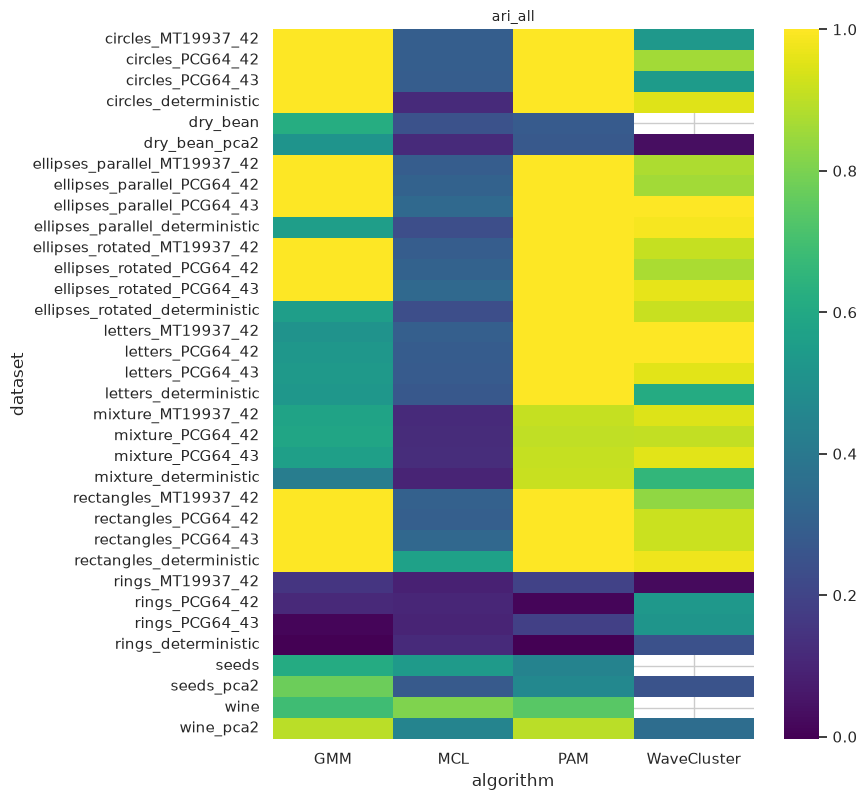

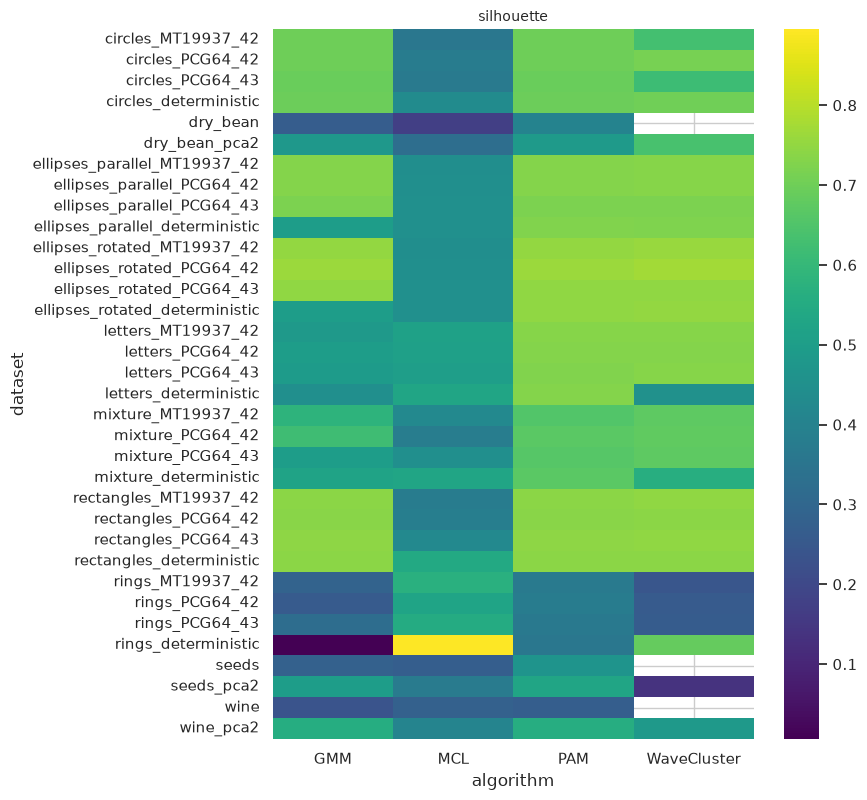

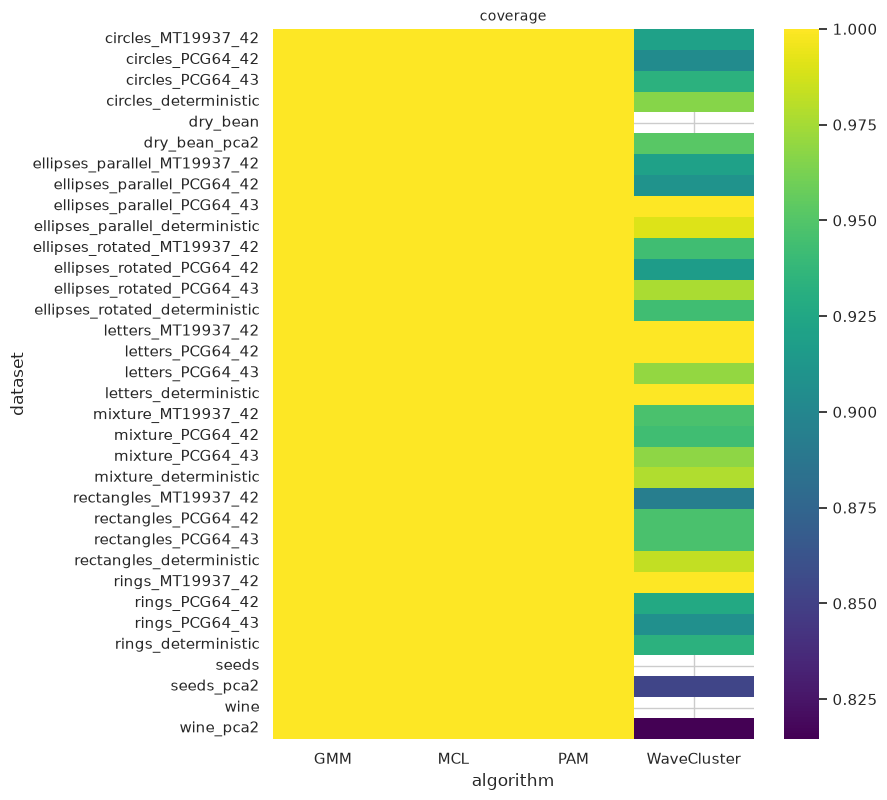

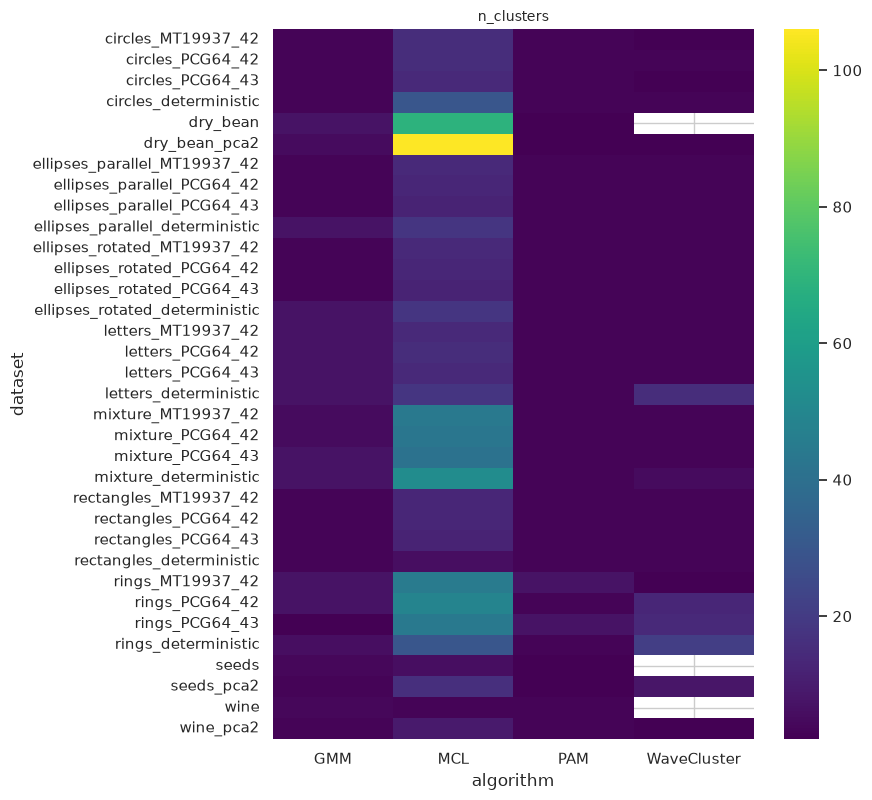

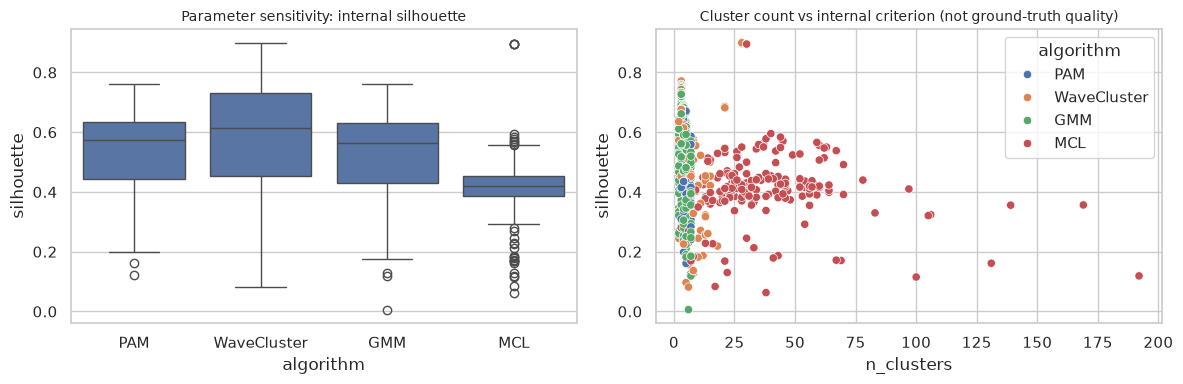

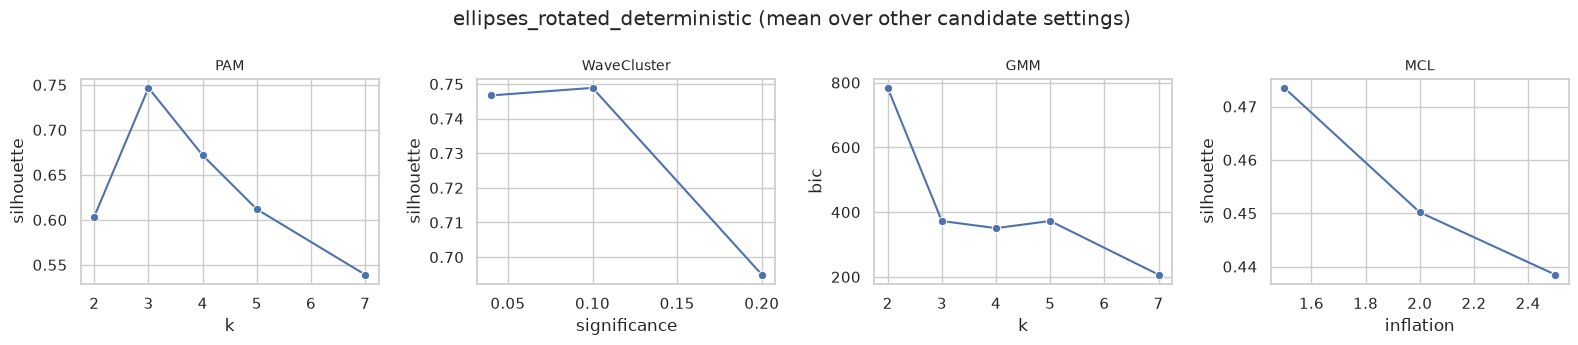

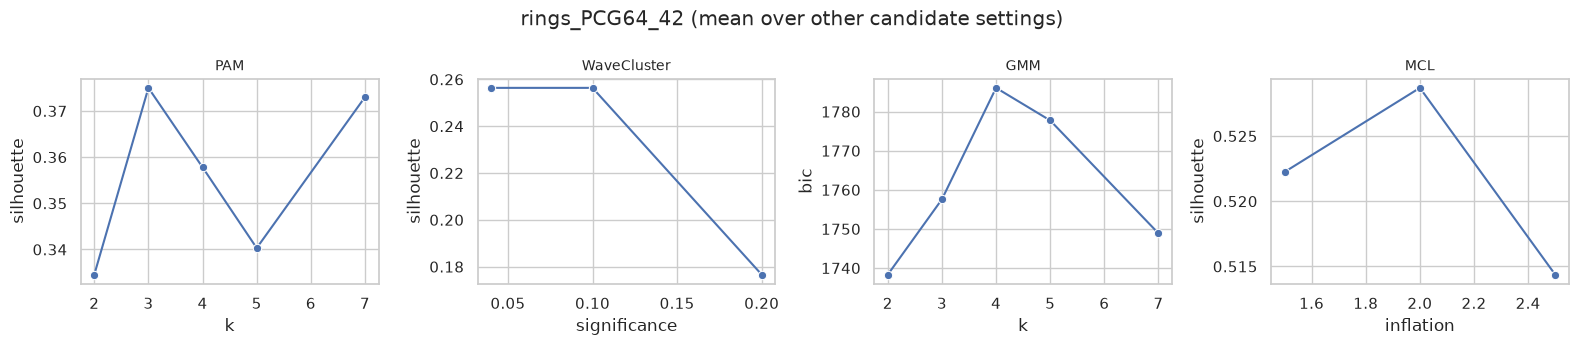

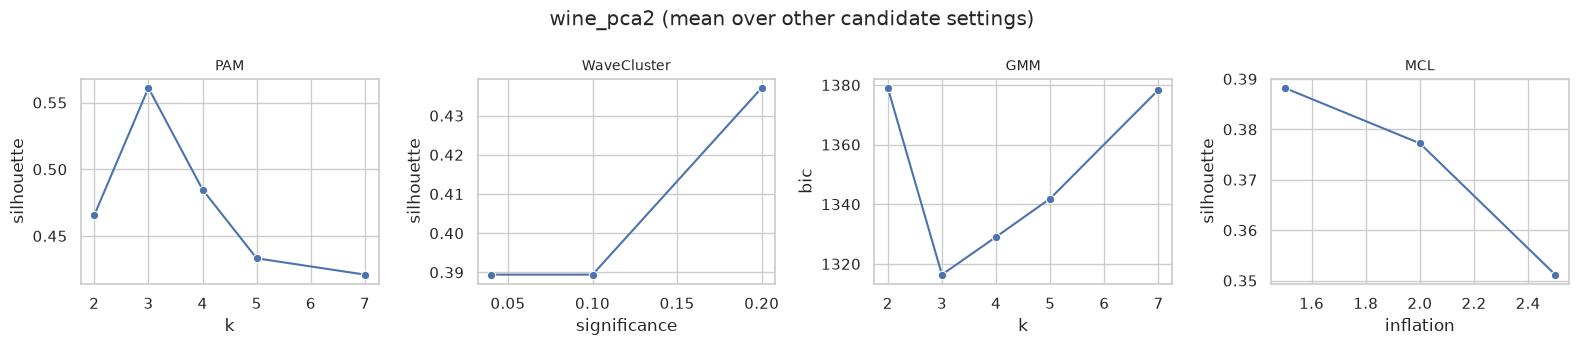

In [42]:
metric_figures(metrics, store)
tuning_figures(parameter_search, store)

**43. Фіксуємо протокол δ-збурень і окремо перевіряємо випадковість алгоритмів.**
Параметри, початковий стан, масштабування та PCA незмінні. δ вимірюється
відносно медіани додатних попарних відстаней. Зміна seed — окремий контроль.

In [43]:
randomness = randomness_check(records, selected, outputs, store, SEED)
display(randomness)

,dataset,algorithm,seed,ari_to_baseline
0,wine_pca2,PAM,42,1.00000
1,wine_pca2,PAM,43,1.00000
2,wine_pca2,PAM,44,1.00000
3,wine_pca2,WaveCluster,42,1.00000
4,wine_pca2,WaveCluster,43,1.00000
5,wine_pca2,WaveCluster,44,1.00000
6,wine_pca2,GMM,42,1.00000
7,wine_pca2,GMM,43,1.00000
8,wine_pca2,GMM,44,0.98165
9,wine_pca2,MCL,42,1.00000


**44. Визначаємо внутрішні, граничні та шумові або розріджені точки для збурень.**
Ролі визначаємо за поточним розбиттям і локальним сусідством, не за еталонними класами.

In [ ]:
from src.experiments import representative_points, characteristic_distance

perturbation_targets = []
for name in illustrative_names:
    for algorithm, result in outputs[name].items():
        for role, point in representative_points(
            records[name]["X"], result.labels
        ).items():
            perturbation_targets.append(
                {
                    "dataset": name,
                    "algorithm": algorithm,
                    "role": role,
                    "point": point,
                    "distance_scale": characteristic_distance(records[name]["X"]),
                }
            )
store.table("stability/targets", pd.DataFrame(perturbation_targets))
display(pd.DataFrame(perturbation_targets).head(12))

,dataset,algorithm,role,point,distance_scale
0,ellipses_rotated_deterministic,PAM,interior,220,1.621519
1,ellipses_rotated_deterministic,PAM,boundary,9,1.621519
2,ellipses_rotated_deterministic,PAM,sparse,59,1.621519
3,ellipses_rotated_deterministic,WaveCluster,interior,170,1.621519
4,ellipses_rotated_deterministic,WaveCluster,boundary,132,1.621519
5,ellipses_rotated_deterministic,WaveCluster,noise,9,1.621519
6,ellipses_rotated_deterministic,GMM,interior,243,1.621519
7,ellipses_rotated_deterministic,GMM,boundary,10,1.621519
8,ellipses_rotated_deterministic,GMM,sparse,59,1.621519
9,ellipses_rotated_deterministic,MCL,interior,123,1.621519


**45. Переміщуємо точки та повторюємо кластеризацію для різних δ і напрямків.**
У full додатково переміщуємо групи з трьох сусідніх точок. MCL перебудовує граф;
межі сітки WaveCluster залишаються початковими.

In [ ]:
stability_results, stability_examples = stability(
    records, selected, outputs, store, MODE, SEED
)
display(
    stability_results.groupby(["algorithm", "status"])
    .size()
    .rename("runs")
    .reset_index()
)

,algorithm,status,runs
0,GMM,ok,96
1,MCL,ok,96
2,PAM,ok,96
3,WaveCluster,ok,96


**46. Порівнюємо розбиття через ARI, узгоджені призначення та переходи між кластером і шумом.**
Номери кластерів узгоджуються оптимальним зіставленням; роль шуму фіксована.

In [ ]:
stability_summary = (
    stability_results[stability_results.status == "ok"]
    .groupby(["dataset", "algorithm", "delta_relative"])
    .agg(
        ari_mean=("ari", "mean"),
        ari_min=("ari", "min"),
        changed_mean=("changed_fraction", "mean"),
        noise_transitions_mean=("noise_transitions", "mean"),
    )
    .reset_index()
)
store.table("stability/summary", stability_summary)
display(stability_summary.head(16))

,dataset,algorithm,delta_relative,ari_mean,ari_min,changed_mean,noise_transitions_mean
0,ellipses_rotated_deterministic,GMM,0.001,0.977402,0.819219,0.013333,0.000
1,ellipses_rotated_deterministic,GMM,0.010,0.932207,0.819219,0.040000,0.000
2,ellipses_rotated_deterministic,GMM,0.050,0.932207,0.819219,0.040000,0.000
3,ellipses_rotated_deterministic,GMM,0.100,0.954805,0.819219,0.026667,0.000
4,ellipses_rotated_deterministic,MCL,0.001,1.000000,1.000000,0.000000,0.000
5,ellipses_rotated_deterministic,MCL,0.010,0.999100,0.992798,0.000417,0.000
6,ellipses_rotated_deterministic,MCL,0.050,0.997308,0.992798,0.001250,0.000
7,ellipses_rotated_deterministic,MCL,0.100,0.981523,0.942463,0.012083,0.000
8,ellipses_rotated_deterministic,PAM,0.001,1.000000,1.000000,0.000000,0.000
9,ellipses_rotated_deterministic,PAM,0.010,1.000000,1.000000,0.000000,0.000


**47. Візуалізуємо стабільність і приклади найбільших змін кластеризації.**

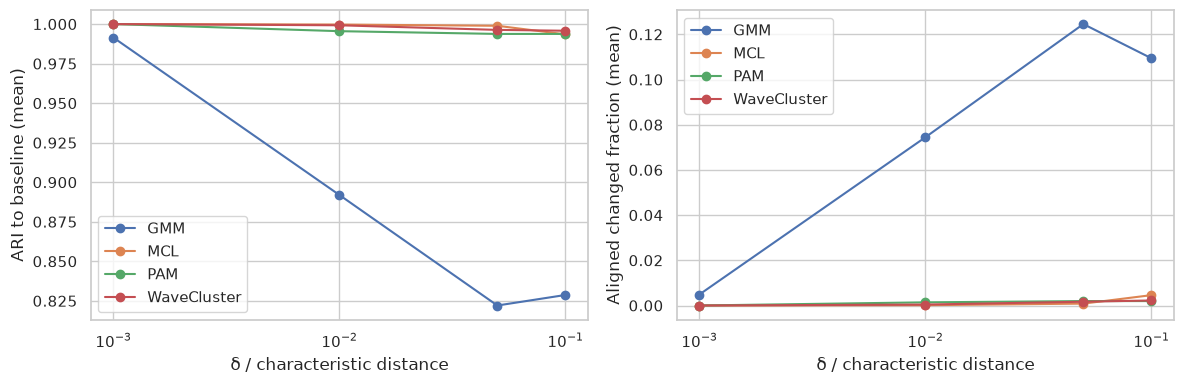

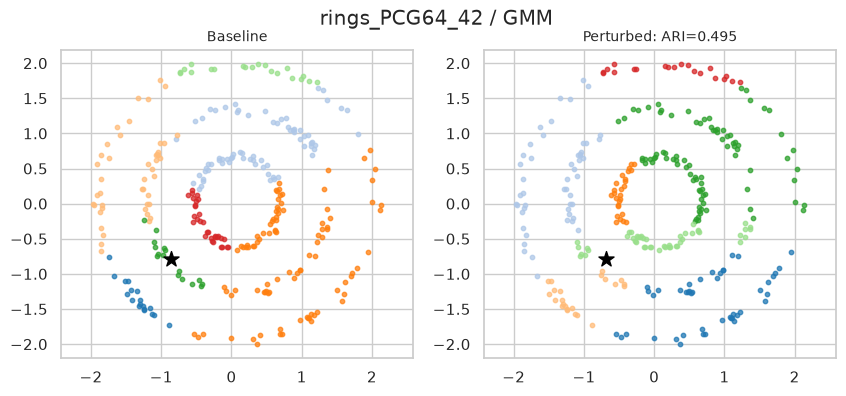

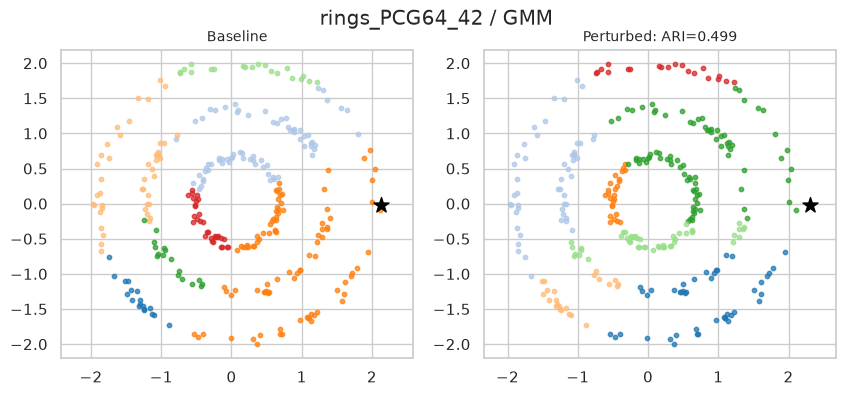

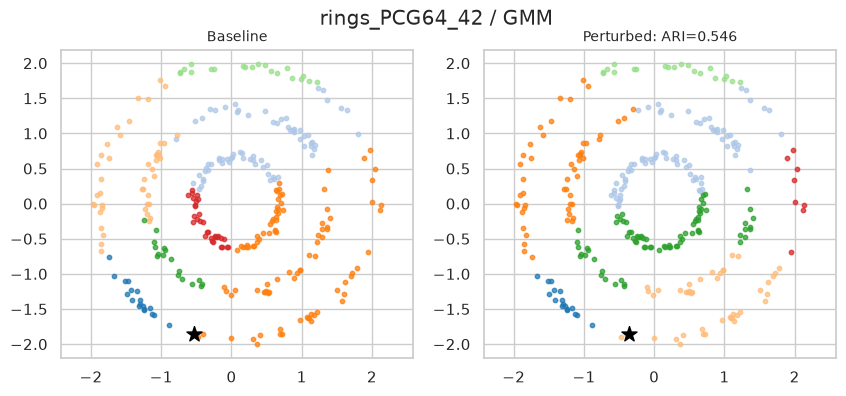

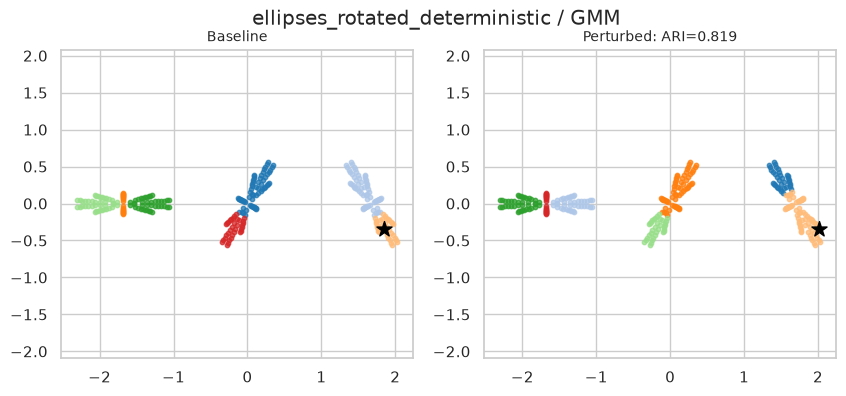

In [ ]:
stability_figures(stability_results, store)
for number, (record, algorithm, before, after, moved, indices, ari) in enumerate(
    sorted(stability_examples, key=lambda item: item[-1])[:4]
):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    scatter(axes[0], record["X"], before, "Baseline")
    scatter(axes[1], moved, after, f"Perturbed: ARI={ari:.3f}")
    for ax, data in zip(axes, (record["X"], moved)):
        ax.scatter(*data[indices].T, marker="*", s=130, c="black")
    fig.suptitle(f"{record['name']} / {algorithm}")
    store.figure(f"stability/example_{number}", fig)

**48. Визначаємо ізольовані ресурсні тести та їхні обмеження.**
Кожен fit — новий процес із одним обчислювальним потоком. Таймер включає
матрицю відстаней, граф або сітку, але не імпорт, завантаження й малювання.
RSS опитується кожні 5 мс: короткі піки можуть залишитися непоміченими.

In [ ]:
print(
    {
        "sizes": [120, 300] if MODE == "quick" else [150, 300, 600, 1200],
        "repetitions": 2 if MODE == "quick" else 3,
        "fit_timeout_seconds": 60,
        "additional_rss_limit_mb": 1024,
        "sources": ["synthetic"] if MODE == "quick" else ["synthetic", "dry_bean_pca2"],
    }
)

{'sizes': [150, 300, 600, 1200], 'repetitions': 3, 'fit_timeout_seconds': 60, 'additional_rss_limit_mb': 1024, 'sources': ['synthetic', 'dry_bean_pca2']}


**49. Вимірюємо час і пам’ять в окремих процесах та зберігаємо сирі вимірювання.**

In [ ]:
benchmark_raw, benchmark_summary = run_benchmarks(benchmark_records, store, MODE, SEED)
display(
    benchmark_raw.groupby(["algorithm", "status"]).size().rename("runs").reset_index()
)

,algorithm,status,runs
0,GMM,ok,24
1,MCL,ok,24
2,PAM,ok,24
3,WaveCluster,ok,24


**50. Порівнюємо масштабування за кількістю об’єктів на однакових 2D-входах.**
Розмірність у цьому ресурсному експерименті фіксована; зростання розмірності
не досліджується, оскільки реалізація WaveCluster обмежена двома вимірами.

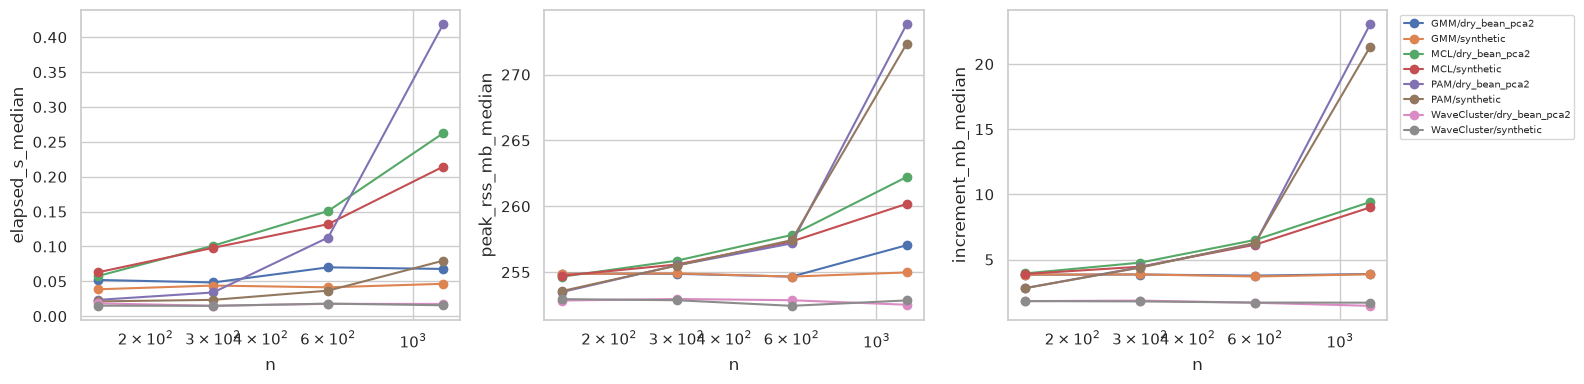

In [50]:
benchmark_figures(benchmark_summary, store)

**51. Переглядаємо медіани, міжквартильний розкид і перевищення ресурсних лімітів.**

In [51]:
display(benchmark_summary)
display(benchmark_raw.loc[benchmark_raw.status != "ok"])

,source,algorithm,n,status,successful_repeats,total_repeats,elapsed_s_median,elapsed_s_q25,elapsed_s_q75,peak_rss_mb_median,peak_rss_mb_q25,peak_rss_mb_q75,baseline_rss_mb_median,baseline_rss_mb_q25,baseline_rss_mb_q75,increment_mb_median,increment_mb_q25,increment_mb_q75
0,dry_bean_pca2,GMM,150,ok,3,3,0.052012,0.051764,0.052446,254.878906,254.841797,254.927734,251.042969,251.007812,251.087891,3.835938,3.833984,3.839844
1,dry_bean_pca2,GMM,300,ok,3,3,0.048382,0.047719,0.057785,254.871094,254.849609,254.939453,251.046875,250.988281,251.101562,3.851562,3.837891,3.875000
2,dry_bean_pca2,GMM,600,ok,3,3,0.070073,0.069532,0.070126,254.660156,254.525391,254.912109,250.878906,250.751953,251.154297,3.765625,3.750000,3.773438
3,dry_bean_pca2,GMM,1200,ok,3,3,0.067787,0.067579,0.068641,257.042969,255.794922,257.958984,253.050781,251.867188,253.101562,3.890625,3.876953,4.857422
4,dry_bean_pca2,MCL,150,ok,3,3,0.057643,0.057346,0.058998,254.648438,254.570312,254.714844,250.714844,250.630859,250.818359,3.933594,3.896484,3.939453
5,dry_bean_pca2,MCL,300,ok,3,3,0.101092,0.100445,0.101464,255.867188,255.742188,255.953125,251.105469,250.964844,251.222656,4.761719,4.730469,4.777344
6,dry_bean_pca2,MCL,600,ok,3,3,0.150848,0.150421,0.152369,257.816406,257.326172,257.869141,251.308594,251.035156,251.310547,6.503906,6.289062,6.558594
7,dry_bean_pca2,MCL,1200,ok,3,3,0.262530,0.261839,0.264937,262.222656,261.419922,262.318359,252.808594,252.000000,252.935547,9.414062,9.382812,9.419922
8,dry_bean_pca2,PAM,150,ok,3,3,0.023427,0.023310,0.025584,253.480469,253.419922,253.486328,250.675781,250.615234,250.693359,2.804688,2.787109,2.810547
9,dry_bean_pca2,PAM,300,ok,3,3,0.034025,0.033916,0.034255,255.511719,255.445312,256.414062,251.003906,250.960938,251.050781,4.414062,4.394531,5.406250


,source,algorithm,n,d,repetition,baseline_rss_mb,peak_rss_mb,increment_mb,sampling_interval_ms,status,elapsed_s,lifetime_highwater_mb,n_clusters


**52. Зберігаємо підсумкові таблиці для майбутнього звіту без змішування представлень.**

In [ ]:
quality_summary = (
    metrics[metrics.status == "ok"]
    .groupby(["kind", "representation", "algorithm"])
    .agg(
        ari_mean=("ari_all", "mean"),
        ari_std=("ari_all", "std"),
        coverage_mean=("coverage", "mean"),
        datasets=("dataset", "count"),
    )
    .reset_index()
)
store.table("metrics/summary_by_track", quality_summary)
display(quality_summary)

,kind,representation,algorithm,ari_mean,ari_std,coverage_mean,datasets
0,real,original_scaled,GMM,0.638288,0.043549,1.000000,3
1,real,original_scaled,MCL,0.530796,0.276735,1.000000,3
2,real,original_scaled,PAM,0.488251,0.233935,1.000000,3
3,real,pca2,GMM,0.728914,0.193246,1.000000,3
4,real,pca2,MCL,0.282161,0.166079,1.000000,3
5,real,pca2,PAM,0.544645,0.318093,1.000000,3
6,real,pca2,WaveCluster,0.213037,0.164086,0.872885,3
7,synthetic,original_scaled,GMM,0.700807,0.342487,1.000000,28
8,synthetic,original_scaled,MCL,0.243766,0.109876,1.000000,28
9,synthetic,original_scaled,PAM,0.858147,0.320006,1.000000,28
